# Sprint 3 · Semana 7: hiperparámetros, importancia de variables, equivalencia validada y variante D3

Tesis: Detección Automatizada y Priorización de Eventos Adversos en Notas Clínicas mediante un Flujo de Procesamiento (Pipeline) de NLP y Aprendizaje Automático — Aplicación de la Matriz de Priorización del Modelo GEMSES sobre MIMIC-IV

Autor: Carlos Pérez Pérez · Curso: MIA-14 Trabajo de Investigación II · Docente: Dr. Glen Rodríguez · 30 de octubre de 2026

El presente cuaderno reúne en un solo documento el trabajo de la semana 7, el cual abre el Sprint 3 en cuatro partes. La primera busca
los hiperparámetros del modelo vigente y la segunda analiza la importancia de sus variables. La tercera presenta la equivalencia de los
códigos CIE-10 de la etiqueta con los eventos oficiales del Anexo N.º 02, validada por el autor, y la cuarta prueba la variante D3 de los
datos, que se deriva de esa validación.

El cuaderno no vuelve a entrenar ningún modelo, sino que lee los resultados que dejan los *scripts* de cada parte en la carpeta
`reportes/` y la equivalencia de `data/catalogos/`, y a partir de ellos construye cada tabla y cada figura. De esta manera, cada cifra
del texto puede verificarse en las celdas de código, salvo la que se rotula como cálculo aparte, y no se requiere acceso a los datos de MIMIC-IV, protegidos por el acuerdo de uso de
PhysioNet. Las partes 1 y 2 reproducen los cuadernos 04 y 05 de la misma rama, con la numeración de tablas y figuras de este documento.

Contenido:

1) Búsqueda de hiperparámetros, aleatoria y bayesiana.
2) Importancia de variables del modelo vigente.
3) Equivalencia de los códigos CIE-10 con los eventos del Anexo N.º 02, validada por el autor.
4) Variante D3, con las negativas que libera la equivalencia validada.
5) Conclusiones de la semana 7.

## 1. Búsqueda de hiperparámetros, aleatoria y bayesiana

Esta parte abre el Sprint 3 con la búsqueda de hiperparámetros del modelo vigente, es decir, la configuración A+B+C entrenada con la
variante D2 de los datos. Las tablas y figuras se construyen con los resultados que deja el *script* `src/experimentos_hp.py`, cuya
corrida completa requirió cerca de 1.8 horas de cómputo.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import figuras_hp  # mismas funciones que dibujan reportes/figuras/fig_hp_*.png

leer = lambda n: json.loads((RAIZ / "reportes" / n).read_text(encoding="utf-8"))
R, D = leer("hp_resultados.json"), leer("datos_resultados.json")
ens = pd.read_csv(RAIZ / "reportes" / "hp_ensayos.csv", keep_default_na=False)
plt.rcParams.update({"font.size": 9})
print("Resultados leídos:", R["generado"], "· semilla", R["semilla"], "· Optuna", R["optuna"], "· decisión:", R["decision"])

Resultados leídos: 2026-10-28T10:17:34 · semilla 42 · Optuna 5.0.0 · decisión: se mantiene la configuración actual


### 1.1 Punto de partida: el modelo vigente

Al cierre del Sprint 2 se adoptó la variante D2 con la configuración A+B+C. Su PR-AUC (área bajo la curva de precisión y sensibilidad) fue
0.8534 ± 0.0041 en la validación cruzada de 5 *folds* y 0.8671 en *test*, en ambos casos sobre las epicrisis
sin etiqueta dudosa. Ese modelo conservó los hiperparámetros (valores que se fijan antes de entrenar y que el modelo no aprende de los datos)
del *baseline* de la semana 3. Esos valores son C igual a 1, clases balanceadas y 20 000 palabras con
`min_df` de 3, y la semana 5 los repitió para los bigramas. Por ello, el cierre del Sprint 2 recomendó ajustar C con pocos
valores, y en esta semana esa recomendación se amplía a una búsqueda que incluye también el tamaño del vocabulario, el peso de las clases y la
forma de contar las palabras.

In [2]:
cv6, te6 = D["cv"]["D2"]["comun"]["pr_auc"], D["test"]["D2"]["comun"]
print("D2 con A+B+C · validación cruzada (5 folds):", cv6["media"], "±", cv6["std"], "· test:", te6["pr_auc"], te6["pr_auc_ic95_pacientes"])

D2 con A+B+C · validación cruzada (5 folds): 0.8534 ± 0.0041 · test: 0.8671 [0.8589, 0.8749]


Fuente: elaboración propia a partir de `reportes/datos_resultados.json`.

### 1.2 Búsqueda aleatoria frente a búsqueda bayesiana

Bergstra y Bengio (2012) señalan que, con el mismo presupuesto, los ensayos elegidos al azar son más eficientes que los de una grilla. Según
los mismos autores, en cada conjunto de datos solo unos pocos hiperparámetros influyen de verdad en el resultado, y esos pocos no son los
mismos de un conjunto a otro. Por ello, proponen la búsqueda aleatoria como punto de comparación de los métodos que eligen cada ensayo a partir
de los resultados de los anteriores, grupo al cual pertenece la búsqueda bayesiana.

La búsqueda bayesiana de este experimento usa Optuna (Akiba et al., 2019), en concreto el estimador TPE (*Tree-structured Parzen Estimator*)
multivariado, que es la opción por defecto de Optuna 5.0.0 cuando hay un solo objetivo. La documentación de Optuna remite, entre otros, a
Bergstra et al. (2011) y, para la variante multivariada, a Falkner et al. (2018). El TPE separa los ensayos ya hechos en los de mejor resultado
y el resto. En su variante multivariada, estima con cada grupo una distribución conjunta de todos los hiperparámetros y propone la
configuración en la que la primera distribución es más alta en relación con la segunda.

En consecuencia, la comparación responde a una pregunta práctica, es decir, si aprender de los ensayos anteriores encuentra una configuración
mejor que el azar cuando ambos métodos disponen del mismo número de ensayos.

### 1.3 Diseño del experimento, fijado antes de ver los resultados

El diseño, el presupuesto y la regla de decisión se escribieron en `config/config.yaml` (sección `hiperparametros`) antes de ejecutar la
búsqueda. Dado que ese archivo no tiene un *commit* anterior a la corrida, la única prueba de ese prerregistro es el registro
`logs/experimentos_hp_20261028_081924.log`, escrito al construir la caché de conteos y antes del primer ensayo. Ese registro recoge el espacio
de búsqueda, la regla de decisión y el presupuesto inicial de 18 ensayos por método.

Se mantuvo el modelo A+B+C sin cambios de diseño, es decir, las palabras de la epicrisis (A), los pares de palabras consecutivas (B) y las
variables de la hospitalización con el largo de la nota (C), seguidos de una regresión logística. Se entrenó con las filas de la variante D2,
igual que en `src/experimentos_datos.py`, y cada configuración se evaluó en las epicrisis de validación sin etiqueta dudosa, que son las mismas
con las cuales se eligió D2 en la semana 6.

La búsqueda se hizo solo en la partición de entrenamiento, con validación cruzada `StratifiedGroupKFold` de 3 *folds*
(partes en que se divide el conjunto de entrenamiento para entrenar con las demás y evaluar con la que queda) y semilla 42. La división se hizo
por paciente, de modo que un paciente nunca está en dos partes, y se usaron 3 *folds* y no 5 para reducir el tiempo de
cada ensayo. La mejor configuración se confirmó después frente a la actual con los 5 *folds* del proyecto, los mismos
de las semanas 5 y 6, y la partición de *test* se usó una sola vez, al final, para esas dos configuraciones.

La métrica es la PR-AUC media de los *folds*, como en las semanas anteriores, y además se registraron la ROC-AUC y el tiempo de cada ensayo.
El Cuadro 1 presenta los hiperparámetros que se buscaron, los valores probados y los de la configuración actual.

Cuadro 1. Espacio de búsqueda

| Hiperparámetro | Qué controla | Valores probados | Configuración actual |
|---|---|---|---|
| C | inverso de la fuerza de la regularización de la regresión logística (a mayor C, menos se penalizan los coeficientes) | continuo, log-uniforme entre 0.001 y 100 | 1 |
| `max_features` de A | número máximo de palabras del vocabulario | 10 000, 20 000, 40 000 y 60 000 | 20 000 |
| `min_df` de A | número mínimo de epicrisis en las que debe aparecer una palabra | 2, 3 y 5 | 3 |
| `max_features` de B | número máximo de bigramas del vocabulario | 10 000, 20 000 y 40 000 | 20 000 |
| `min_df` de B | número mínimo de epicrisis en las que debe aparecer un bigrama | 2, 3 y 5 | 3 |
| `class_weight` | peso de las clases en el entrenamiento | *balanced* (compensa la proporción de cada clase) o sin pesos | *balanced* |
| `sublinear_tf` | cuenta las repeticiones de un término como 1 + log(frecuencia) y no como la frecuencia | activado o desactivado, con el mismo valor en A y en B | activado |

Fuente: elaboración propia a partir de `config/config.yaml`. El valor de 60 000 palabras corresponde al modelo de la tesis registrado en la
sección `baseline` del mismo archivo, y `sublinear_tf` se cambia sobre el *pipeline* de `src/features.py` sin modificar sus bloques.

Se compararon dos métodos con el mismo presupuesto de 15 ensayos cada uno, ambos con Optuna 5.0.0 y semilla 42, es decir, la
búsqueda aleatoria (`RandomSampler`) y la bayesiana (`TPESampler` multivariado). La bayesiana empieza con 5 ensayos al azar y, como usa la
misma semilla, esos ensayos coinciden con los 5 primeros de la aleatoria, por lo cual se evaluaron una sola vez y se reutilizaron. De esta
manera, ambos métodos parten del mismo punto, y la diferencia entre ellos se debe solo a la forma de elegir los ensayos siguientes.

El presupuesto se fijó primero en 18 ensayos por método y se redujo a 15 antes de iniciar la búsqueda, por una estimación previa de que los
ensayos con C alto tardarían varios minutos cada uno. Esa estimación no quedó registrada, y los dos valores del presupuesto constan en los
registros de las corridas en `logs/`. Asimismo, la corrida no fijó el parámetro `multivariate` del `TPESampler`, de modo que se aplicó el
valor por defecto de Optuna 5.0.0, que con un solo objetivo equivale a `multivariate=True`. Después de la corrida, ese valor se hizo explícito
en el *script* y en `config/config.yaml`, y la segunda celda de código que sigue verifica que la secuencia de ensayos que propone es idéntica a la registrada.

La regla de decisión, también fijada antes de correr, establece que la configuración ajustada reemplaza a la actual solo si mejora la PR-AUC de
la validación cruzada de 5 *folds* en al menos 4 de ellos. Además, la mejora media debe superar
una desviación estándar de las diferencias por *fold*, y si no se cumplen
las dos condiciones se mantiene la configuración actual. Para no repetir la comparación con varias configuraciones, la candidata es una sola,
la de mayor PR-AUC media entre los ensayos de los dos métodos.

Es preciso tomar en consideración que el lote de la revisión ciega de las hipótesis específicas HE2 y HE3 ya se generó con la configuración
actual (D2, A+B+C, corte de probabilidad 0.5), y que esa revisión está en curso. Por consiguiente, si la regla adoptara otra configuración, el
lote no se regenera, y se declara que HE2 y HE3 se refieren a la configuración con la cual se muestreó.

In [3]:
H = R["parametros"]
print("Configuración actual:", R["configuracion_actual"])
print("Presupuesto:", H["n_ensayos"], "ensayos por método · ensayos iniciales al azar de la bayesiana:", H["ensayos_iniciales_tpe"],
      "· folds de búsqueda:", H["n_folds_busqueda"], "· folds de confirmación:", H["n_folds_confirmacion"])
print("Regla:", H["regla"])
print("Protocolo:", R["protocolo"])
for f in sorted((RAIZ / "logs").glob("experimentos_hp_2*.log")):     # corrida de la caché y corrida principal
    lineas = f.read_text(encoding="utf-8").splitlines()
    print(f.name, "·", lineas[0][:19], "·", next(l for l in lineas if "presupuesto:" in l).split(" | ")[-1])
    print("   ", next(l for l in lineas if "REGLA PRERREGISTRADA" in l).split(" | ")[-1][:110], "…")

Configuración actual: {'C': 1.0, 'A_max_features': 20000, 'A_min_df': 3, 'B_max_features': 20000, 'B_min_df': 3, 'class_weight': 'balanced', 'sublinear_tf': True}
Presupuesto: 15 ensayos por método · ensayos iniciales al azar de la bayesiana: 5 · folds de búsqueda: 3 · folds de confirmación: 5
Regla: {'folds_mejores_minimo': 4, 'desviaciones_minimas': 1.0}
Protocolo: búsqueda: StratifiedGroupKFold(3, shuffle=True, random_state=42) por subject_id en train; confirmación: StratifiedGroupKFold(5, shuffle=True, random_state=42) (los folds de las semanas 5 y 6); entrenan las filas de D2; métrica: PR-AUC media en las epicrisis de validación sin etiqueta dudosa; test usado una vez
experimentos_hp_20261028_081924.log · 2026-10-28 08:19:24 · presupuesto: 18 ensayos por método · bayesiana con 5 ensayos iniciales al azar
    REGLA PRERREGISTRADA: la candidata reemplaza a la actual solo si mejora la PR-AUC (5 folds) en al menos 4 de 5 …
experimentos_hp_20261028_084713.log · 2026-10-28 08:47:13 · pr

In [4]:
# Verificación del TPE multivariado: se vuelve a pedir a Optuna la secuencia de ensayos, respondiendo con la PR-AUC
# registrada en hp_ensayos.csv (sin entrenar), y se compara con los parámetros que propuso la corrida real.
import numpy as np
import optuna
import experimentos_hp as hp          # espacio de búsqueda del script
%matplotlib inline

optuna.logging.set_verbosity(optuna.logging.WARNING)
cols = list(R["configuracion_actual"])
reg = pd.read_csv(RAIZ / "reportes" / "hp_ensayos.csv", keep_default_na=False, float_precision="round_trip")
igual = lambda p, r: all(np.isclose(p[c], r[c], rtol=1e-12) if c == "C" else p[c] == r[c] for c in cols)

def repetir(sampler):
    sugeridos = []
    def objetivo(trial):
        p = hp.espacio(trial, H["espacio"])
        sugeridos.append(p)
        r = next((r for r in reg.to_dict("records") if igual(p, r)), None)
        if r is None:
            raise optuna.TrialPruned()      # la secuencia ya se separó de la registrada
        return r["pr_auc_media"]
    optuna.create_study(direction="maximize", sampler=sampler).optimize(objetivo, n_trials=H["n_ensayos"])
    return sugeridos

S, k0 = R["semilla"], H["ensayos_iniciales_tpe"]
for nombre, metodo, sampler in (
        ("RandomSampler(seed=42)", "aleatoria", optuna.samplers.RandomSampler(seed=S)),
        ("TPESampler(seed=42, multivariate=True)", "bayesiana", optuna.samplers.TPESampler(seed=S, n_startup_trials=k0, multivariate=True)),
        ("TPESampler(seed=42, multivariate=False), control", "bayesiana",
         optuna.samplers.TPESampler(seed=S, n_startup_trials=k0, multivariate=False))):
    r_m = reg[reg.metodo == metodo].sort_values("ensayo").to_dict("records")
    print(f"{nombre}: {sum(igual(p, r) for p, r in zip(repetir(sampler), r_m))} de {len(r_m)} ensayos iguales a los registrados")

RandomSampler(seed=42): 15 de 15 ensayos iguales a los registrados
TPESampler(seed=42, multivariate=True): 15 de 15 ensayos iguales a los registrados
TPESampler(seed=42, multivariate=False), control: 5 de 15 ensayos iguales a los registrados


Como se aprecia en la salida anterior, con `multivariate=True` explícito Optuna propone los mismos 15 ensayos bayesianos que registró la
corrida, mientras que con el TPE independiente (`multivariate=False`) la secuencia solo coincide en los 5 ensayos iniciales al azar. De esta
manera, se confirma que la corrida usó el TPE multivariado.

Para que cada ensayo tarde minutos y no horas, en cada partición las palabras y los bigramas se contaron una sola vez y los conteos se
guardaron en una caché. Así, cada ensayo solo elige el vocabulario con la misma regla de scikit-learn y aplica la ponderación TF-IDF, con
matrices idénticas a las del *pipeline* de `src/features.py`. El *script* incluye un control de esa equivalencia contra el propio *pipeline*, que
se ejecuta con la opción `--prueba` sobre una muestra de 4 000 epicrisis de *train*, y su registro se conserva en `logs/`. Adicionalmente, la
sección 1.4 verifica que la configuración actual reproduce los resultados de la semana 6.

In [5]:
prueba = sorted((RAIZ / "logs").glob("experimentos_hp_prueba_*.log"))[-1]
lineas = prueba.read_text(encoding="utf-8").splitlines()
print(prueba.name, "·", next(l for l in lineas if "pacientes compartidos" in l).split(" | ")[-1])
print(next(l for l in lineas if "control de equivalencia" in l).split(" | ")[-1])

experimentos_hp_prueba_20261028_104516.log · train 4,000 (entrenan 3,527 filas de D2; evaluación común 3,527) · test 1,500 (evaluación común 1,302) · 0 pacientes compartidos
control de equivalencia con el pipeline de features.py (C=3.7 · A 10000/5 · B 10000/2 · class_weight=ninguno · sublinear_tf=False): diferencia máxima de probabilidad 0.00e+00


### 1.4 Control de reproducción

Como se aprecia en la Tabla 1, la configuración actual medida en esta corrida reproduce la PR-AUC por *fold* de D2 que registró la semana 6,
sin diferencias hasta el sexto decimal (diferencia máxima de 0.000000). De igual forma, en *test* se obtuvo 0.8671
en las epicrisis sin etiqueta dudosa, frente a 0.8671 de la semana 6, y 0.8580 con
todas las epicrisis, frente a 0.8580. De esta manera, se confirma que la búsqueda parte del mismo modelo y de los
mismos datos que la semana anterior.

In [6]:
c, t = R["control_reproduccion_cv"], R["control_reproduccion_test"]
t1 = pd.DataFrame({"semana 6 (D2)": c["pr_auc_semana6"], "esta corrida (actual)": c["pr_auc_esta_corrida"]},
                  index=pd.Index(range(1, len(c["pr_auc_semana6"]) + 1), name="Tabla 1. PR-AUC por fold (5 folds)"))
display(t1)
print("Diferencia máxima:", c["dif_maxima"], "· reproduce:", c["reproduce"])
print("Test sin etiqueta dudosa:", t["pr_auc_comun_semana6"], "→", t["pr_auc_comun_esta_corrida"],
      "· todas las epicrisis:", t["pr_auc_completa_semana6"], "→", t["pr_auc_completa_esta_corrida"], "· reproduce:", t["reproduce"])

,semana 6 (D2),esta corrida (actual)
Tabla 1. PR-AUC por fold (5 folds),,
1,0.856697,0.856697
2,0.852738,0.852738
3,0.846717,0.846717
4,0.854189,0.854189
5,0.856627,0.856627


Diferencia máxima: 0.0 · reproduce: True
Test sin etiqueta dudosa: 0.8671 → 0.8671 · todas las epicrisis: 0.858 → 0.858 · reproduce: True


Fuente: elaboración propia a partir de `reportes/hp_resultados.json` y `reportes/datos_folds.csv`.

### 1.5 Resultados de la búsqueda

La Tabla 2 presenta los cinco mejores ensayos de cada método, ordenados por la PR-AUC media de 3 *folds*, con sus
hiperparámetros, la desviación estándar entre *folds*, la ROC-AUC y el tiempo de cómputo de cada ensayo. En total se registraron 30
ensayos, 15 por método, que corresponden a 25 configuraciones distintas, dado que los 5 primeros ensayos de la bayesiana se
reutilizaron de la aleatoria.

In [7]:
cols = ["C", "A_max_features", "A_min_df", "B_max_features", "B_min_df", "class_weight", "sublinear_tf", "pr_auc_media", "pr_auc_std",
        "roc_auc_media", "segundos", "reutilizado_de"]
t2 = (ens.sort_values("pr_auc_media", ascending=False).groupby("metodo", sort=False).head(5)
         .sort_values(["metodo", "pr_auc_media"], ascending=[True, False]).set_index(["metodo", "ensayo"])[cols])
t2.index.names = ["Tabla 2. Método", "ensayo"]
display(t2.style.format({"C": "{:.4g}", "pr_auc_media": "{:.4f}", "pr_auc_std": "{:.4f}", "roc_auc_media": "{:.4f}", "segundos": "{:.0f}"}))
ref = R["referencia_actual_busqueda"]
print("Configuración actual en los mismos 3 folds: PR-AUC", round(ref["pr_auc_media"], 4), "±", round(ref["pr_auc_std"], 4),
      "· ROC-AUC", round(ref["roc_auc_media"], 4))
for m, r in R["mejor_por_metodo"].items():
    print(f"Mejor {m}: ensayo {r['ensayo']} · PR-AUC {r['pr_auc_media']:.4f} ± {r['pr_auc_std']:.4f} · diferencia con la actual "
          f"{r['pr_auc_media'] - ref['pr_auc_media']:+.4f}")
print("Candidata:", R["candidata"])
print("Ensayos registrados:", len(ens), "· configuraciones distintas evaluadas:", int((ens.reutilizado_de == "").sum()),
      "· mejor bayesiana menos mejor aleatoria:", round(R["mejor_por_metodo"]["bayesiana"]["pr_auc_media"] - R["mejor_por_metodo"]["aleatoria"]["pr_auc_media"], 4))

Configuración actual en los mismos 3 folds: PR-AUC 0.8498 ± 0.0009 · ROC-AUC 0.8546
Mejor aleatoria: ensayo 4 · PR-AUC 0.8471 ± 0.0014 · diferencia con la actual -0.0027
Mejor bayesiana: ensayo 14 · PR-AUC 0.8480 ± 0.0024 · diferencia con la actual -0.0018
Candidata: {'metodo': 'bayesiana', 'parametros': {'C': 2.318133815156313, 'A_max_features': 10000, 'A_min_df': 3, 'B_max_features': 10000, 'B_min_df': 2, 'class_weight': 'ninguno', 'sublinear_tf': False}}
Ensayos registrados: 30 · configuraciones distintas evaluadas: 25 · mejor bayesiana menos mejor aleatoria: 0.0009


Fuente: elaboración propia a partir de `reportes/hp_ensayos.csv` y `reportes/hp_resultados.json`.


Como se aprecia en la Tabla 2, el mejor ensayo de la búsqueda aleatoria fue el n.º 4, el cual alcanzó una PR-AUC de
0.8471 ± 0.0014. Sus hiperparámetros fueron C de 0.976, 10 000 palabras con `min_df` de 3, 10 000 bigramas con `min_df` de 5, `class_weight` sin pesos y `sublinear_tf` activado. Por su parte, el mejor de la
bayesiana fue el n.º 14, el cual alcanzó 0.8480 ± 0.0024 con C de 2.32, 10 000 palabras con `min_df` de 3, 10 000 bigramas con `min_df` de 2, `class_weight` sin pesos y `sublinear_tf` desactivado. Este
último pasó a ser la candidata, por tener la mayor PR-AUC media de los dos métodos. Sin embargo, la configuración actual obtuvo 0.8498 ± 0.0009 en los mismos 3 *folds*,
de modo que ningún ensayo de los dos métodos la superó, y la candidata quedó
0.0018 por debajo de ella.

Figura 1. Mejor resultado acumulado y resultado de cada ensayo, por método

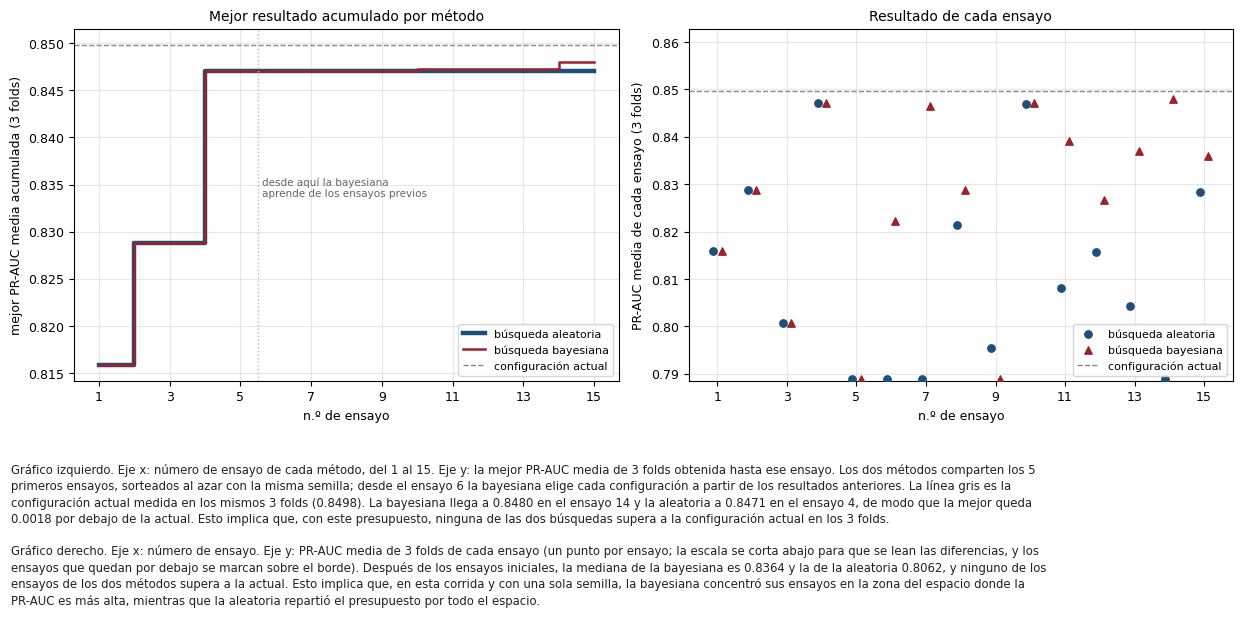

In [8]:
fig = figuras_hp.fig_busqueda(R, ens)
plt.show()

Fuente: elaboración propia a partir de `reportes/hp_ensayos.csv`.


En la Figura 1 se observa que las dos búsquedas recorren el mismo camino durante los 5 ensayos iniciales, en los cuales el mejor resultado
acumulado llega a 0.8471. A partir del ensayo 6, la aleatoria no vuelve a mejorar, mientras que la bayesiana mejora en los ensayos 10 y 14 (hasta 0.8480), y ninguna de
las dos alcanza la línea de la configuración actual. Asimismo, en el gráfico derecho se aprecia que, después de los ensayos iniciales, la
mediana de la bayesiana (0.8364) supera a la de la aleatoria (0.8062). Esta diferencia es
coherente con que el TPE propuso C de al menos 0.1 en 9 de sus 10 ensayos propios, frente a 4 de
10 de la aleatoria en los mismos ensayos, y evitó así la zona de C pequeño donde la PR-AUC cae. En consecuencia,
en esta corrida y con una sola semilla, la búsqueda bayesiana aprovechó mejor el presupuesto, en el sentido de que evaluó menos configuraciones
con PR-AUC baja. Aun así, con 15 ensayos su mejor resultado superó al de la aleatoria en solo 0.0009.

In [9]:
k0 = R["parametros"]["ensayos_iniciales_tpe"]
for m, g in ens.groupby("metodo", sort=False):
    v = g.sort_values("ensayo")
    print(f"{m}: mejor acumulado por ensayo", [round(x, 4) for x in v.pr_auc_media.cummax()],
          f"· mediana después del ensayo {k0}: {v[v.ensayo > k0].pr_auc_media.median():.4f}",
          f"· ensayos sobre la actual: {(v.pr_auc_media > R['referencia_actual_busqueda']['pr_auc_media']).sum()}",
          f"· ensayos propios (después del {k0}) con C de al menos 0.1: {(v[v.ensayo > k0].C >= 0.1).sum()} de {(v.ensayo > k0).sum()}")

aleatoria: mejor acumulado por ensayo [0.8158, 0.8288, 0.8288, 0.8471, 0.8471, 0.8471, 0.8471, 0.8471, 0.8471, 0.8471, 0.8471, 0.8471, 0.8471, 0.8471, 0.8471] · mediana después del ensayo 5: 0.8062 · ensayos sobre la actual: 0 · ensayos propios (después del 5) con C de al menos 0.1: 4 de 10
bayesiana: mejor acumulado por ensayo [0.8158, 0.8288, 0.8288, 0.8471, 0.8471, 0.8471, 0.8471, 0.8471, 0.8471, 0.8472, 0.8472, 0.8472, 0.8472, 0.848, 0.848] · mediana después del ensayo 5: 0.8364 · ensayos sobre la actual: 0 · ensayos propios (después del 5) con C de al menos 0.1: 9 de 10


La Figura 2 muestra cómo cambia la PR-AUC de la búsqueda con cada hiperparámetro, con un punto por cada una de las 25 configuraciones
evaluadas. El panel a) presenta el efecto de C y los paneles b) a g), el de los demás hiperparámetros.

Figura 2. Efecto de cada hiperparámetro en la PR-AUC de la búsqueda

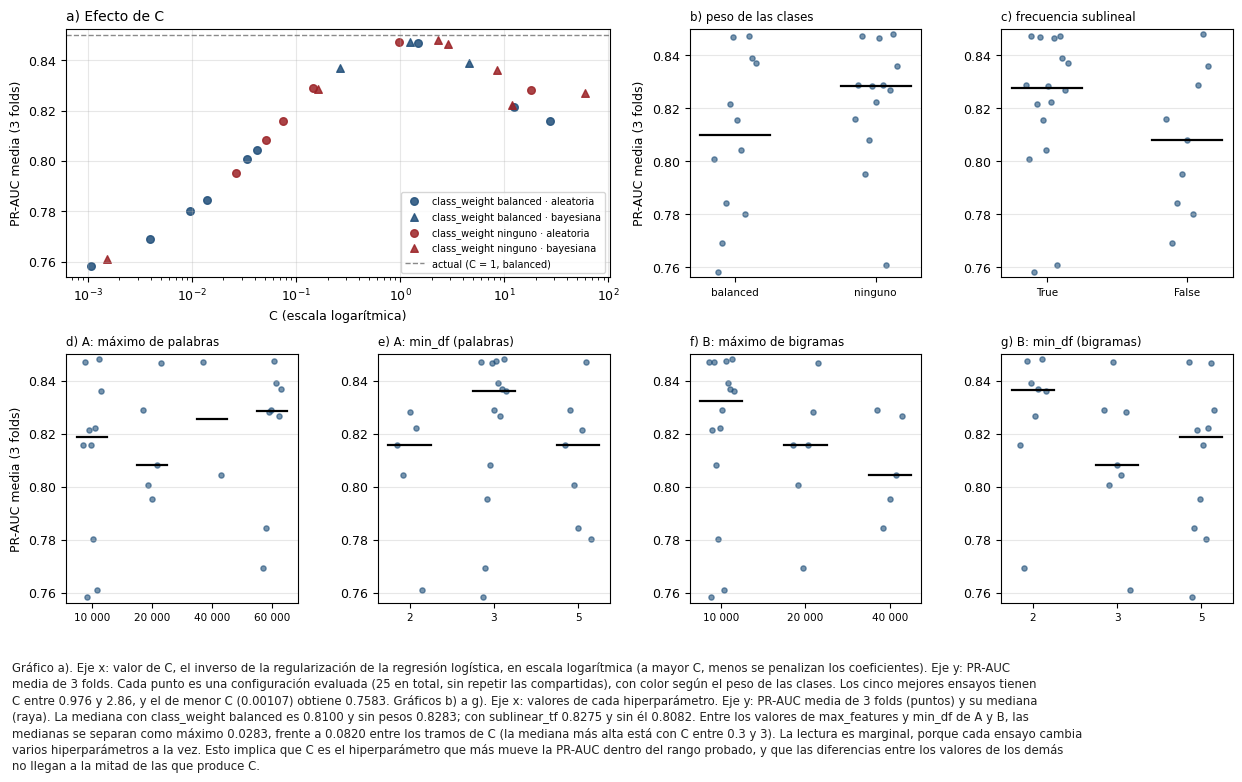

In [10]:
fig = figuras_hp.fig_parametros(R, ens)
plt.show()

Fuente: elaboración propia a partir de `reportes/hp_ensayos.csv`.


En el panel a) de la Figura 2 se observa que la PR-AUC sube con C hasta un máximo en torno a C = 1 y luego desciende. A criterio del autor,
este comportamiento refleja el paso de una regularización excesiva, que impide al modelo aprovechar el texto, a una regularización escasa, que
lo ajusta en exceso a las epicrisis de entrenamiento. Por el contrario, en los paneles b) a g) las medianas de los demás hiperparámetros se
separan bastante menos, y esas diferencias reflejan en parte los valores de C con los cuales coincidieron en cada ensayo, por lo cual se leen
solo como orientación. La Tabla 3 resume el efecto de C por tramos.

In [11]:
u = ens[ens.reutilizado_de == ""]
tramos = pd.cut(u.C, figuras_hp.TRAMOS_C, labels=["hasta 0.01", "0.01 a 0.1", "0.1 a 0.3", "0.3 a 3", "más de 3"])
t3 = u.groupby(tramos, observed=True).pr_auc_media.agg(["count", "median", "max"]).round(4)
t3.columns = ["configuraciones", "PR-AUC mediana", "PR-AUC máxima"]
t3.index.name = "Tabla 3. Tramo de C"
display(t3)
print("Mediana por class_weight:", u.groupby("class_weight").pr_auc_media.median().round(4).to_dict(),
      "· por sublinear_tf:", u.groupby("sublinear_tf").pr_auc_media.median().round(4).to_dict())

,configuraciones,PR-AUC mediana,PR-AUC máxima
Tabla 3. Tramo de C,,,
hasta 0.01,4,0.7651,0.7802
0.01 a 0.1,6,0.8025,0.8158
0.1 a 0.3,3,0.8288,0.8369
0.3 a 3,5,0.8471,0.8480
más de 3,7,0.8268,0.8390


Mediana por class_weight: {'balanced': 0.81, 'ninguno': 0.8283} · por sublinear_tf: {False: 0.8082, True: 0.8275}


Fuente: elaboración propia a partir de `reportes/hp_ensayos.csv`.


Como se aprecia en la Tabla 3, la mediana de la PR-AUC pasa de 0.7651 con C hasta 0.01 a 0.8471 con C entre
0.3 y 3, y vuelve a bajar a 0.8268 con C mayor que 3. De igual forma, la
mediana es de 0.8100 con `class_weight` *balanced* y de 0.8283 sin pesos, y de 0.8275 con `sublinear_tf` activado y
de 0.8082 sin él, diferencias menores que las que produce C. De esta manera, la configuración actual, con C de 1, ya se
encuentra en el tramo de C con la PR-AUC más alta, lo cual es coherente con que la búsqueda no la haya superado.

### 1.6 Confirmación con los 5 *folds* del proyecto y aplicación de la regla

Siguiendo el diseño, la candidata, es decir, el ensayo 14 de la búsqueda bayesiana, se comparó con la configuración actual en los
5 *folds* del proyecto, sobre las mismas epicrisis de validación sin etiqueta dudosa. La Tabla 4 presenta la PR-AUC de ambas
configuraciones en cada *fold* y la diferencia entre ellas, con su media y su desviación estándar.

In [12]:
c = R["confirmacion_5_folds"]
pa = [f["pr_auc_comun"] for f in c["actual"]["folds"]]
pc = [f["pr_auc_comun"] for f in c["candidata"]["folds"]]
t4 = pd.DataFrame({"actual": pa, "candidata": pc}, index=pd.Index(range(1, len(pa) + 1), name="Tabla 4. PR-AUC por fold (5 folds)"))
t4["candidata − actual"] = t4.candidata - t4.actual
t4.loc["media"] = t4.iloc[:5].mean(); t4.loc["desviación estándar"] = t4.iloc[:5].std()
display(t4.round(4))
g = R["regla"]
print("Folds en que mejora la candidata:", g["folds_mejores"], "de", g["n_folds"], "· criterio de folds (al menos", g["folds_mejores_minimo"], "):", g["criterio_folds"])
print("Diferencia media:", g["dif_media"], "· desviación estándar:", g["dif_std"], "· criterio de desviación:", g["criterio_desviacion"])
print("ROC-AUC media (5 folds): actual", round(c["actual"]["roc_auc_media"], 4), "· candidata", round(c["candidata"]["roc_auc_media"], 4))
print("Diferencias por fold con 6 decimales:", [f"{x:+.6f}" for x in g["diferencias_por_fold"]])
print("Decisión:", R["decision"])

,actual,candidata,candidata − actual
Tabla 4. PR-AUC por fold (5 folds),,,
1,0.8567,0.8567,-0.0000
2,0.8527,0.8513,-0.0014
3,0.8467,0.8435,-0.0032
4,0.8542,0.8521,-0.0021
5,0.8566,0.8562,-0.0005
media,0.8534,0.8519,-0.0014
desviación estándar,0.0041,0.0053,0.0013


Folds en que mejora la candidata: 0 de 5 · criterio de folds (al menos 4 ): False
Diferencia media: -0.001444 · desviación estándar: 0.001274 · criterio de desviación: False
ROC-AUC media (5 folds): actual 0.8582 · candidata 0.855
Diferencias por fold con 6 decimales: ['-0.000034', '-0.001398', '-0.003199', '-0.002125', '-0.000465']
Decisión: se mantiene la configuración actual


Fuente: elaboración propia a partir de `reportes/hp_resultados.json`.

Figura 3. Confirmación con los 5 *folds* del proyecto

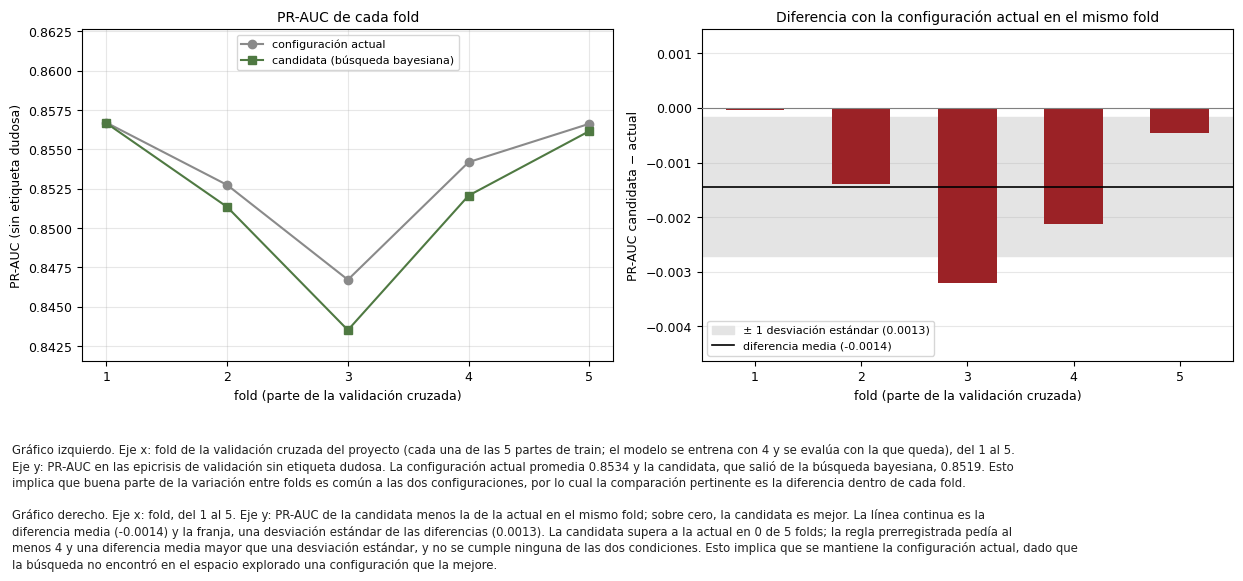

In [13]:
fig = figuras_hp.fig_folds(R)
plt.show()

Fuente: elaboración propia a partir de `reportes/hp_resultados.json`.


Como se aprecia en la Tabla 4 y en la Figura 3, la candidata no superó a la configuración actual en ninguno de los 5 *folds*, con una diferencia media de -0.0014 y una desviación estándar de
0.0013. La mayor diferencia en contra se dio en el *fold* 3 (-0.0032), mientras que en el *fold* 1 ambas casi
coinciden (-0.000034). Por consiguiente, no se cumple ninguna de las dos condiciones de la regla, dado que se exigía una mejora en al menos 4 de los
5 *folds* y una diferencia media mayor que una desviación estándar, y se mantiene la configuración actual. Asimismo, la ROC-AUC media de los
5 *folds* también fue menor con la candidata (0.8550 frente a 0.8582).

### 1.7 Medición única en *test*

Una vez aplicada la regla, la configuración actual y la candidata se reentrenaron con todas las filas de entrenamiento de D2 y se midieron una
sola vez en la partición de *test*. La Tabla 5 presenta el resultado, con el intervalo de confianza al 95% obtenido al remuestrear pacientes
200 veces.

In [14]:
filas = {}
for k in ("actual", "candidata"):
    for ev, nombre in (("comun", "sin etiqueta dudosa"), ("completa", "todas, etiqueta original")):
        t = R["test"][k][ev]
        filas[f"{k} · {nombre}"] = {"PR-AUC": t["pr_auc"], "IC 95% (pacientes)": f"{t['pr_auc_ic95_pacientes'][0]:.4f} a {t['pr_auc_ic95_pacientes'][1]:.4f}",
                                    "ROC-AUC": t["roc_auc"], "sensibilidad": t["recall"], "especificidad": t["especificidad"]}
t5 = pd.DataFrame(filas).T
t5.index.name = "Tabla 5. Test (medición única)"
t5.style.format(lambda x: f"{x:.4f}" if isinstance(x, float) else x)

,PR-AUC,IC 95% (pacientes),ROC-AUC,sensibilidad,especificidad
Tabla 5. Test (medición única),,,,,
actual · sin etiqueta dudosa,0.8671,0.8589 a 0.8749,0.8706,0.7689,0.8038
"actual · todas, etiqueta original",0.8580,0.8493 a 0.8664,0.8398,0.7189,0.7950
candidata · sin etiqueta dudosa,0.8645,0.8567 a 0.8719,0.8666,0.7629,0.8035
"candidata · todas, etiqueta original",0.8555,0.8464 a 0.8637,0.8359,0.7131,0.7950


Fuente: elaboración propia a partir de `reportes/hp_resultados.json`.


Como se aprecia en la Tabla 5, en las epicrisis sin etiqueta dudosa la PR-AUC fue de 0.8671 con la configuración actual
y de 0.8645 con la candidata, y con todas las epicrisis fue de 0.8580 y
0.8555, respectivamente. De esta manera, el *test* repite el orden de la validación cruzada, aunque los intervalos de
confianza se solapan (0.8589 a 0.8749 frente a 0.8567 a 0.8719), por lo cual la decisión se apoya en la
comparación por *fold* y no en esta medición.

### 1.8 Traducción a eventos adversos por cada 10 000 hospitalizaciones

Al igual que en la semana 6, se aplicaron la sensibilidad y la especificidad medidas en *test* con el umbral de 0.5 a 10 000 hospitalizaciones
con epicrisis, con la prevalencia real de 27.6%, es decir, 2 759 hospitalizaciones con evento según los códigos. La
Tabla 6 presenta el resultado para la configuración actual y para la candidata, en las epicrisis sin etiqueta dudosa y con todas las epicrisis.

In [15]:
t6 = pd.DataFrame({f"{k} · {nombre}": R["test"][k][f"por_10000_{ev}"] for k in ("actual", "candidata")
                   for ev, nombre in (("comun", "sin etiqueta dudosa"), ("completa", "todas, etiqueta original"))}).T
t6.columns = ["con evento", "detectados (VP)", "se escapan (FN)", "falsas alarmas (FP)", "VPP: de cada 100 alertas, con evento"]
t6.index.name = f"Tabla 6. Por cada 10 000 hospitalizaciones (prevalencia real {100 * R['prevalencia_real_con_epicrisis']:.1f}%)"
t6

,con evento,detectados (VP),se escapan (FN),falsas alarmas (FP),"VPP: de cada 100 alertas, con evento"
Tabla 6. Por cada 10 000 hospitalizaciones (prevalencia real 27.6%),,,,,
actual · sin etiqueta dudosa,2759,2121,638,1421,60
"actual · todas, etiqueta original",2759,1983,776,1484,57
candidata · sin etiqueta dudosa,2759,2105,654,1423,60
"candidata · todas, etiqueta original",2759,1967,792,1484,57


Fuente: elaboración propia a partir de `reportes/hp_resultados.json`.


Como se aprecia en la Tabla 6, en las epicrisis sin etiqueta dudosa la candidata detectaría 16 eventos
menos que la configuración actual (2 105 frente a 2 121) y daría
2 falsas alarmas más (1 423 frente a
1 421). En ambas configuraciones, 60 de cada 100 alertas tendrían evento.
Con todas las epicrisis y la etiqueta original, la candidata detectaría 16 eventos menos
(1 967 frente a 1 983) y
el mismo número de falsas alarmas.

Es preciso tomar en consideración que este cálculo supone que las tasas medidas en *test* valen para toda la base, y que los eventos son los
que marcan los códigos CIE y no el resultado de una revisión clínica de cada nota. Asimismo, la diferencia entre ambas configuraciones queda
dentro de los intervalos de confianza de la Tabla 5, por lo cual estas cifras se toman solo como orden de magnitud y no como una pérdida
demostrada.

### 1.9 Tiempo de cómputo

La Tabla 7 presenta el tiempo de cada etapa, en minutos, tal como lo midió el propio *script*.

In [16]:
NOMBRE = {"conteos_calculo_original": "conteo de palabras y bigramas (9 particiones)", "busqueda_aleatoria": "búsqueda aleatoria (reloj)",
          "busqueda_bayesiana": "búsqueda bayesiana (reloj)", "referencia_actual_busqueda": "configuración actual en 3 folds",
          "busqueda_calculo_original": "búsqueda completa (suma de ensayos y referencia)", "confirmacion": "confirmación (5 folds)",
          "test": "medición en test", "esta_corrida": "corrida principal (sin el conteo)", "computo_total": "cómputo total"}
t7 = pd.Series(R["tiempos_segundos"]).div(60).round(1).rename(NOMBRE).rename("minutos").to_frame()
t7.index.name = "Tabla 7. Etapa"
display(t7)
u = ens[ens.reutilizado_de == ""]
print("Ensayo más largo:", round(u.segundos.max() / 60, 1), "min · más corto:", round(u.segundos.min() / 60, 1), "min",
      "· cómputo total:", round(R["tiempos_segundos"]["computo_total"] / 3600, 1), "horas")

,minutos
Tabla 7. Etapa,
conteo de palabras y bigramas (9 particiones),20.3
búsqueda aleatoria (reloj),32.9
búsqueda bayesiana (reloj),37.8
configuración actual en 3 folds,2.6
búsqueda completa (suma de ensayos y referencia),73.2
confirmación (5 folds),13.3
medición en test,3.5
corrida principal (sin el conteo),90.3
cómputo total,110.3


Ensayo más largo: 8.5 min · más corto: 0.3 min · cómputo total: 1.8 horas


Fuente: elaboración propia a partir de `reportes/hp_resultados.json`.


Como se aprecia en la Tabla 7, el cómputo total fue de 110.3 minutos (1.8 horas). De ese
total, 20.3 minutos correspondieron a contar las palabras y los bigramas de las 9 particiones
(3 de búsqueda, 5 de confirmación y la de *test*), y 73.2
a la búsqueda, incluida la configuración actual en los 3 *folds* de búsqueda. Los restantes 13.3
y 3.5 minutos correspondieron a la confirmación y a la medición en *test*, respectivamente.

La caché de conteos se construyó en una corrida previa con la opción `--solo-conteos`, por lo cual la corrida principal duró
90.3 minutos. Asimismo, los ensayos con C alto fueron los más lentos (el más largo tardó 8.5
minutos y el más corto 0.3). De esta manera, la búsqueda bayesiana ocupó 37.8 minutos de
reloj frente a 32.9 de la aleatoria, aun con 5 ensayos reutilizados.

### 1.10 Decisión y siguiente paso

Una vez analizados los resultados, se concluye que ninguna de las 25 configuraciones evaluadas superó a la configuración actual en los
3 *folds* de búsqueda. Asimismo, la mejor de ellas, confirmada con los 5 *folds* del proyecto, quedó por
debajo en 5 de los 5 *folds*. Por consiguiente, y en aplicación de la regla fijada antes de
correr, se mantiene la configuración actual, es decir, D2 con A+B+C, C de 1, 20 000 palabras con `min_df` de 3, 20 000 bigramas con `min_df` de 3, `class_weight` *balanced* y `sublinear_tf` activado. De acuerdo con la Tabla 3, esa configuración ya se encuentra en la zona de mejor
desempeño del espacio explorado.

La comparación de los métodos muestra que, en esta corrida y con una sola semilla, la búsqueda bayesiana concentró mejor sus ensayos que la
aleatoria. Sin embargo, con 15 ensayos su mejor resultado solo superó al de la aleatoria en 0.0009 de
PR-AUC, diferencia menor que la desviación entre *folds* de la propia candidata (0.0024). Por ello, con una sola repetición no
se puede afirmar que un método sea mejor que el otro. Dado que se mantiene la configuración actual, HE2 y HE3 se refieren a la misma
configuración con la cual se generó el lote de la revisión ciega.

Se recomienda, como siguiente experimento del Sprint 3, evaluar el modelo por servicio, grupo de edad y decil de largo de la nota frente al
modelo de contexto, y recalibrar las probabilidades a la prevalencia real. Para reproducir el experimento se ejecuta
`python src/experimentos_hp.py`, el cual guarda en `data/interim/cache_hp/`, fuera de git, los conteos y los resultados de cada evaluación.
Una nueva corrida reutiliza esos archivos, y para repetir todo desde cero se borra esa carpeta; la corrida completa requirió
1.8 horas de cómputo en CPU.

## 2. Importancia de variables del modelo vigente

Esta parte analiza la importancia de las variables del modelo que confirmó la búsqueda de hiperparámetros de la parte 1. Las tablas y
figuras se construyen con los resultados que deja el *script* `src/importancia_variables.py`, cuyo cálculo tomó 20.3 minutos.

In [17]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import figuras_imp  # mismas funciones que dibujan reportes/figuras/fig_imp_*.png

leer = lambda n: json.loads((RAIZ / "reportes" / n).read_text(encoding="utf-8"))
R, Hp = leer("importancia_resultados.json"), leer("hp_resultados.json")
G = pd.read_csv(RAIZ / "reportes" / "importancia_grupos.csv")
T = pd.read_csv(RAIZ / "reportes" / "importancia_terminos.csv", keep_default_na=False)
plt.rcParams.update({"font.size": 9})
print("Resultados leídos:", R["generado"], "· semilla", R["semilla"], "· modelo", R["modelo"], "con", R["variante"])

Resultados leídos: 2026-10-28T11:51:50 · semilla 42 · modelo A+B+C con D2


### 2.1 Punto de partida: el modelo vigente

En la búsqueda de hiperparámetros de esta misma semana, la regla fijada antes de correr mantuvo la configuración actual, cuya PR-AUC (área
bajo la curva de precisión y sensibilidad) fue 0.8534 ± 0.0041 en la validación cruzada de 5 *folds*. Por
consiguiente, el modelo que se analiza es D2 con A+B+C, es decir, palabras (A) y bigramas (B) de la epicrisis con 20 000 términos cada uno y
`min_df` de 3, y variables de la hospitalización con el largo de la nota (C). La regresión logística usa C de 1, clases balanceadas y la
frecuencia sublineal de `src/features.py`.

In [18]:
print("Decisión de la búsqueda de hiperparámetros:", Hp["decision"])
print("PR-AUC de la configuración actual (5 folds):", round(Hp["confirmacion_5_folds"]["actual"]["pr_auc_media"], 4), "±",
      round(Hp["confirmacion_5_folds"]["actual"]["pr_auc_std"], 4))
print("Configuración analizada:", R["configuracion"])

Decisión de la búsqueda de hiperparámetros: se mantiene la configuración actual
PR-AUC de la configuración actual (5 folds): 0.8534 ± 0.0041
Configuración analizada: {'C': 1.0, 'A_max_features': 20000, 'A_min_df': 3, 'B_max_features': 20000, 'B_min_df': 3, 'class_weight': 'balanced', 'sublinear_tf': True}


Fuente: elaboración propia a partir de `reportes/hp_resultados.json` y `reportes/importancia_resultados.json`.

### 2.2 Diseño del análisis, fijado antes de ver los resultados

La importancia de una variable (cuánto depende el modelo ya entrenado de ella para separar las epicrisis con evento de las que no lo tienen)
se midió de tres maneras complementarias, las cuales resume el Cuadro 2. Los parámetros están en `config/config.yaml` (sección
`importancia`). En el equipo donde se corrió, ese archivo se modificó por última vez a las 11:17 del 28 de octubre de 2026 y el *script* a las
11:31:21, antes de que empezara la corrida, a las 11:31:31. La única prueba de ese orden son las horas de modificación de los archivos, dado
que no hay un *commit* anterior a la corrida.

Cuadro 2. Métodos de importancia

| Método | Qué mide | Cómo se calcula |
|---|---|---|
| Permutación por bloque | cuánto depende el modelo de cada bloque (A, B y C) | se permutan juntas, entre las epicrisis de validación del *fold*, todas las columnas del bloque, 30 veces, y se mide la caída de la PR-AUC |
| Permutación dentro de C | cuánto depende el modelo de cada variable de contexto | lo mismo, por variable original; las columnas *one-hot* y la marca de faltante de una variable se permutan juntas |
| Coeficientes de la regresión | qué términos de A y de B empujan hacia evento o hacia sin evento | los 20 términos de mayor coeficiente positivo y negativo de cada *fold* (el *top*), y su estabilidad entre los 5 *folds* |

Fuente: elaboración propia a partir de `config/config.yaml` y `src/importancia_variables.py`.

La importancia se calculó solo con los 5 *folds* del proyecto (partes en que se divide el conjunto de *train* para entrenar con cuatro y
evaluar con la que queda), separados por paciente y con semilla 42. En cada *fold*, el modelo se entrena con las filas de D2 y se evalúa en las
epicrisis de validación sin etiqueta dudosa, igual que en las semanas 6 y 7. No se usó la partición de *test*, con el fin de no gastarla y de
no anticipar la hipótesis específica HE1.

Asimismo, no se calculó ninguna importancia ni ningún desempeño por servicio, grupo de edad o largo de la nota, dado que esa comparación es la
de HE1 y se reserva para otro momento. Como el modelo es lineal, permutar las filas de un grupo de columnas equivale a permutar su aporte al
*logit*, por lo cual cada permutación no exige volver a transformar el texto.

Antes de mostrar o guardar cualquier término se aplicó el filtro de privacidad del Cuadro 3, exigido por la licencia de PhysioNet. El filtro se
aplicó a los 50 términos de mayor coeficiente de cada signo, bloque y *fold*, y solo los que lo pasan llegan a
`reportes/importancia_terminos.csv` y a las figuras.

Cuadro 3. Filtro de privacidad de los términos

| Criterio | Regla | Origen |
|---|---|---|
| Solo letras | cada palabra del término tiene solo letras a-z, sin dígitos ni el marcador de anonimización ___ | criterio del autor |
| Pacientes | el término aparece en las epicrisis de al menos 100 pacientes distintos de *train* | criterio del autor |
| Epicrisis | el término aparece en al menos el 1% de las epicrisis de *train* (560 de 55 915) | precedente del EDA de la semana 4: `src/eda_texto.py`, línea 21 (`MIN_DF = 0.01`), con el que se publicaron términos de esa frecuencia mínima |
| Nombre propio | ninguna palabra del término va con mayúscula inicial en más del 50% de sus apariciones, en una muestra de 10 000 epicrisis de *train* | criterio del autor (heurístico) |

Fuente: elaboración propia a partir de `config/config.yaml` y `src/eda_texto.py`.

Es preciso tomar en consideración tres límites de interpretación. En primer lugar, la importancia no es causalidad, dado que mide cuánto
depende el modelo de una variable y no si esa variable produce el evento. En segundo lugar, los coeficientes de TF-IDF dependen de la escala de
cada término y de su correlación con los demás, por lo cual se leen como asociación del modelo y no como efecto de la palabra. En tercer lugar,
a criterio del autor, si dos bloques comparten información, la permutación de uno solo puede subestimar su importancia, porque el bloque que
no se permuta conserva parte de esa información.

Por último, los resultados se comparan con la ablación de la semana 5 y con la permutación de la semana 6, que se leen de
`reportes/fe_resultados.json` y `reportes/datos_resultados.json` sin recalcularlas. La lectura clínica de los términos, cuando se hace, va
rotulada como interpretación del autor y no como hallazgo.

In [19]:
print("Partición:", R["particion"])
print("Parámetros:", R["parametros"])
print("Mínimo de epicrisis del filtro:", R["filtro_privacidad"]["min_notas"], "de", R["n_train"], "epicrisis de train",
      f"({R['parametros']['filtro_privacidad']['min_pct_notas']:g}%)")
for f in sorted((RAIZ / "logs").glob("importancia_variables_*.log")):
    print(f.name, "· inicio:", f.read_text(encoding="utf-8").splitlines()[0][:19])

Partición: StratifiedGroupKFold(5, shuffle=True, random_state=42) por subject_id en train; entrenan las filas de D2; se evalúa en las epicrisis de validación sin etiqueta dudosa; no se usa test
Parámetros: {'particion': 'confirmacion', 'n_repeticiones': 30, 'top_terminos': 20, 'candidatos_por_fold': 50, 'mostrar_terminos': 15, 'filtro_privacidad': {'min_pacientes': 100, 'min_pct_notas': 1.0, 'solo_letras': True, 'max_pct_mayuscula_inicial': 50, 'muestra_mayusculas': 10000}}
Mínimo de epicrisis del filtro: 560 de 55915 epicrisis de train (1%)
importancia_variables_20261028_113131.log · inicio: 2026-10-28 11:31:31
importancia_variables_prueba_20261028_123034.log · inicio: 2026-10-28 12:30:34


### 2.3 Control de reproducción y de la caché

El *script* reutiliza los conteos de palabras y bigramas que dejó la búsqueda de hiperparámetros en `data/interim/cache_hp/`. Para comprobar que
esa caché es equivalente, en cada *fold* se ajustaron además los bloques del *pipeline* de `src/features.py` sobre las mismas filas, y las
15 comparaciones (5 *folds* por 3 bloques) dieron matrices idénticas. Asimismo, como se aprecia en la Tabla 8, la PR-AUC de
validación de cada *fold* reproduce la de D2 registrada en la semana 6, con una diferencia máxima de 0.000000.

In [20]:
c = R["control_reproduccion"]
t1 = pd.DataFrame({"semana 6 (D2)": c["pr_auc_semana6"], "esta corrida": c["pr_auc_base_esta_corrida"]},
                  index=pd.Index(range(1, 6), name="Tabla 8. PR-AUC de validación por fold"))
display(t1)
eq = R["equivalencia_cache_pipeline"]
print("Comparaciones caché frente al pipeline:", len(eq["detalle"]), "· todas iguales:", eq["todos_iguales"], "· reproduce la semana 6:", c["reproduce"])

,semana 6 (D2),esta corrida
Tabla 8. PR-AUC de validación por fold,,
1,0.856697,0.856697
2,0.852738,0.852738
3,0.846717,0.846717
4,0.854189,0.854189
5,0.856627,0.856627


Comparaciones caché frente al pipeline: 15 · todas iguales: True · reproduce la semana 6: True


Fuente: elaboración propia a partir de `reportes/importancia_resultados.json` y `reportes/datos_folds.csv`.

El *script* tiene, además, un modo de prueba (`--prueba`) que corre 2 *folds* con 2 permutaciones y escribe sus salidas fuera de git, en
`data/interim/prueba_imp/`; su registro se conserva en `logs/`. Una primera corrida de prueba falló al final por un choque de nombres de
variable en el *script*, el cual se corrigió antes de la corrida completa, y su registro no se conservó. La celda siguiente muestra los
controles del registro de prueba que se conserva.

In [21]:
prueba = sorted((RAIZ / "logs").glob("importancia_variables_prueba_*.log"))[-1]
for l in prueba.read_text(encoding="utf-8").splitlines():
    if "caché igual" in l or "control:" in l or "Salidas" in l:
        print(l.split(" | ")[0][11:], "·", l.split(" | ")[-1][:150])

12:34:28 · fold 1: caché igual al pipeline de features.py en A, B y C: True
12:38:14 · fold 2: caché igual al pipeline de features.py en A, B y C: True
12:41:50 · control: la PR-AUC de cada fold reproduce la semana 6: {'pr_auc_base_esta_corrida': [0.856697, 0.852738], 'pr_auc_semana6': [0.856697, 0.852738], 'dif
12:41:52 · Salidas: data/interim/prueba_imp/metrics_importancia.txt · data/interim/prueba_imp/importancia_resultados.json · data/interim/prueba_imp/importancia_g


### 2.4 Importancia por bloque

La Tabla 9 presenta la caída de la PR-AUC al permutar cada bloque, como media de los 5 *folds*, con su desviación estándar entre *folds*, el
valor de cada *fold* y la desviación media entre las 30 permutaciones de un mismo *fold*.

In [22]:
t2 = pd.DataFrame({k: {"caída media": v["media"], "desviación entre folds": v["std"], "desviación entre permutaciones": v["std_repeticiones_media"],
                       "columnas (media)": round(G[G.grupo == k].n_columnas.mean(), 1), "por fold": [round(x, 4) for x in v["por_fold"]]}
                   for k, v in R["importancia_bloques"].items()}).T
t2.index.name = "Tabla 9. Bloque"
display(t2)
b = G[G.tipo == "bloque"].pivot(index="fold", columns="grupo", values="caida_media")[["A · palabras", "B · bigramas", "C · contexto"]]
print("Suma de las caídas de A y B por separado:", round(R["importancia_bloques"]["A · palabras"]["media"] + R["importancia_bloques"]["B · bigramas"]["media"], 4),
      "· caída de A+B juntos:", R["importancia_bloques"]["A+B · texto completo"]["media"])
print("Orden de los bloques en cada fold:", [" > ".join(r.sort_values(ascending=False).index.str[0]) for _, r in b.iterrows()])

,caída media,desviación entre folds,desviación entre permutaciones,columnas (media),por fold
Tabla 9. Bloque,,,,,
A · palabras,0.12742,0.00276,0.00438,20000.0,"[0.128, 0.1286, 0.1231, 0.1306, 0.1268]"
B · bigramas,0.03309,0.00132,0.002273,20000.0,"[0.0336, 0.031, 0.0332, 0.0346, 0.033]"
C · contexto,0.11063,0.00342,0.003933,91.2,"[0.1106, 0.1148, 0.1075, 0.107, 0.1133]"
A+B · texto completo,0.23492,0.00459,0.005745,40000.0,"[0.2349, 0.2334, 0.2303, 0.2426, 0.2333]"


Suma de las caídas de A y B por separado: 0.1605 · caída de A+B juntos: 0.23492
Orden de los bloques en cada fold: ['A > C > B', 'A > C > B', 'A > C > B', 'A > C > B', 'A > C > B']


Fuente: elaboración propia a partir de `reportes/importancia_resultados.json` y `reportes/importancia_grupos.csv`.

Como se aprecia en la Tabla 9, el bloque de mayor peso es el de las palabras (A), cuya permutación reduce la PR-AUC en 0.1274 ±
0.0028, seguido del contexto (C), con 0.1106 ± 0.0034, y de los bigramas (B), con 0.0331 ±
0.0013. La desviación entre *folds* es pequeña frente a cada caída, de modo que el orden de los tres bloques no depende de cómo se
partieron los datos.

Por otra parte, al permutar juntas las palabras y los bigramas la caída es 0.2349, mayor que la suma de las dos por separado
(0.1605). A criterio del autor, que la caída conjunta supere a la suma es coherente con que ambos bloques compartan
información, aunque no lo demuestra, dado que la caída de la PR-AUC no tiene por qué ser aditiva.

Figura 4. Importancia por bloque y comparación con las semanas 5 y 6

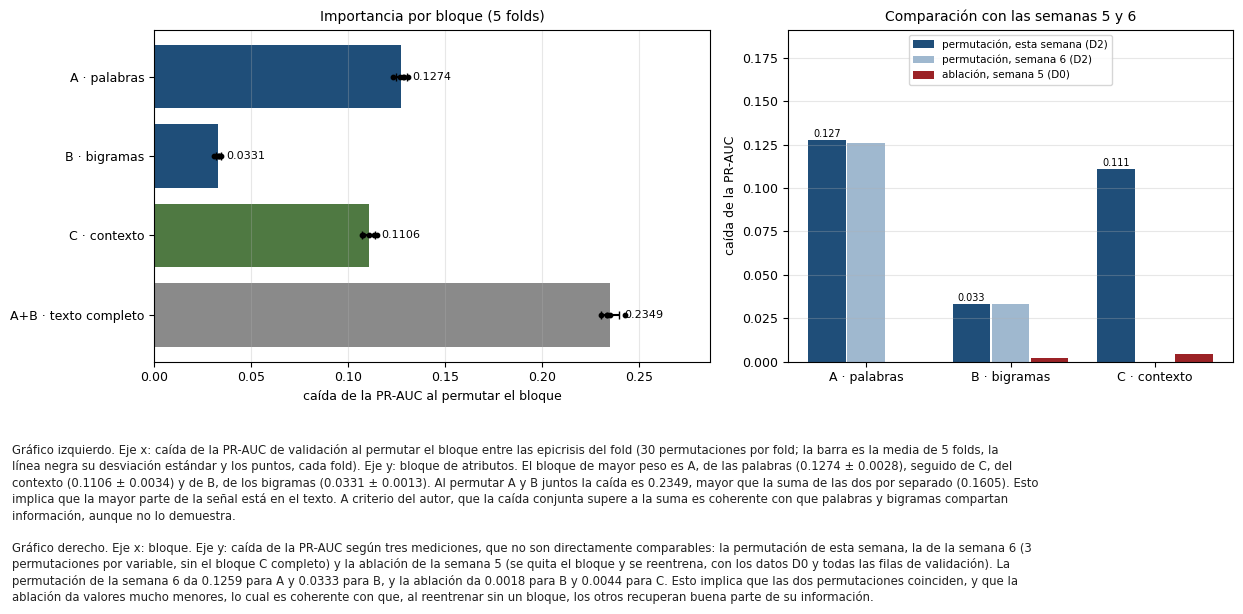

In [23]:
fig = figuras_imp.fig_bloques(R)
plt.show()

Fuente: elaboración propia a partir de `reportes/importancia_resultados.json`, `reportes/fe_resultados.json` y
`reportes/datos_resultados.json`.

En el gráfico derecho de la Figura 4 se observa que la permutación de esta semana coincide con la de la semana 6 en las palabras
(0.1274 frente a 0.1259) y en los bigramas (0.0331 frente a 0.0333).
La semana 6, sin embargo, usó 3 permutaciones por variable y no calculó el bloque C completo. Por el contrario, la ablación de la semana 5, que quita
el bloque y vuelve a entrenar, da caídas mucho menores, de 0.0018 para B y de 0.0044 para C.

In [24]:
cmp = R["comparacion"]
t3 = pd.DataFrame({"permutación, esta semana (D2)": {k[0]: v["media"] for k, v in R["importancia_bloques"].items() if k[0] in "ABC" and "+" not in k},
                   "permutación, semana 6 (D2)": {"A": cmp["permutacion_semana6"]["A"], "B": cmp["permutacion_semana6"]["B"], "C": None},
                   "ablación, semana 5 (D0)": {"A": None, "B": cmp["ablacion_semana5"]["B"], "C": cmp["ablacion_semana5"]["C"]}})
t3.index.name = "Tabla 10. Bloque"
display(t3)
print("Ablación de la semana 5 (PR-AUC en validación cruzada):", {k: cmp["ablacion_semana5"][k] for k in ("A+B+C", "A+C", "A+B")},
      "· contexto sin texto:", cmp["ablacion_semana5"]["C_sin_texto"])

,"permutación, esta semana (D2)","permutación, semana 6 (D2)","ablación, semana 5 (D0)"
Tabla 10. Bloque,,,
A,0.12742,0.1259,NaN
B,0.03309,0.0333,0.0018
C,0.11063,NaN,0.0044


Ablación de la semana 5 (PR-AUC en validación cruzada): {'A+B+C': 0.8732, 'A+C': 0.8714, 'A+B': 0.8688} · contexto sin texto: 0.7771


Fuente: elaboración propia a partir de `reportes/importancia_resultados.json`, `reportes/fe_resultados.json` y
`reportes/datos_resultados.json`.

Como se aprecia en la Tabla 10, las dos mediciones responden a preguntas distintas. La permutación mide cuánto se apoya el modelo ya entrenado
en un bloque, mientras que la ablación mide cuánto pierde un modelo que se entrena sin ese bloque y que, por ello, puede recuperar parte de la
información en los bloques que quedan. A criterio del autor, la distancia entre ambas, sobre todo en el contexto (0.1106 frente a
0.0044), indica que el modelo usa el contexto, pero que el texto contiene casi toda esa información. Es preciso
tomar en consideración, además, que la ablación se midió con los datos D0 y todas las filas de validación, y no con D2.

### 2.5 Importancia de las variables de contexto

La Tabla 11 presenta la caída de la PR-AUC al permutar cada una de las 19 variables del bloque C, ordenadas de mayor a menor, junto con
el valor de la permutación de la semana 6.

In [25]:
s6 = R["comparacion"]["permutacion_semana6"]["variables_de_C"]
t4 = pd.DataFrame({figuras_imp.NOMBRE.get(k, k): {"caída media": v["media"], "desviación entre folds": v["std"],
                                                  "columnas (media)": round(G[G.grupo == k].n_columnas.mean(), 1),
                                                  "semana 6": s6.get(k)} for k, v in R["importancia_contexto"].items()}).T
t4.index.name = "Tabla 11. Variable de contexto"
display(t4)
print("Suma de las caídas por variable:", round(sum(v["media"] for v in R["importancia_contexto"].values()), 4),
      "· bloque C completo:", R["importancia_bloques"]["C · contexto"]["media"],
      "· variables por debajo de 0.0005:", sum(v["media"] < 0.0005 for v in R["importancia_contexto"].values()))

,caída media,desviación entre folds,columnas (media),semana 6
Tabla 11. Variable de contexto,,,,
estancia (días),0.01319,0.00139,2.0,0.0136
servicio al ingreso,0.00613,0.00112,18.0,0.0061
largo de la nota,0.00539,0.00022,2.0,0.0053
servicio al alta,0.00403,0.00083,17.8,0.0044
n.º de cultivos,0.00383,0.00081,1.0,0.0037
destino al alta,0.00369,0.00091,13.4,0.0038
n.º de medicamentos,0.00130,0.00042,1.0,0.0012
tipo de ingreso,0.00081,0.00036,9.0,0.0008
procedencia,0.00076,0.00026,10.0,0.0007


Suma de las caídas por variable: 0.0401 · bloque C completo: 0.11063 · variables por debajo de 0.0005: 10


Fuente: elaboración propia a partir de `reportes/importancia_resultados.json` y `reportes/datos_resultados.json`.

Como se aprecia en la Tabla 11, las tres variables de contexto de mayor peso son estancia (días) (0.0132),
servicio al ingreso (0.0061) y largo de la nota (0.0054), mientras que
10 de las 19 variables quedan por debajo de 0.0005. Asimismo, los valores son muy cercanos a los de la semana 6, que usó el
mismo modelo y los mismos *folds* con menos permutaciones.

Figura 5. Importancia de las variables de contexto

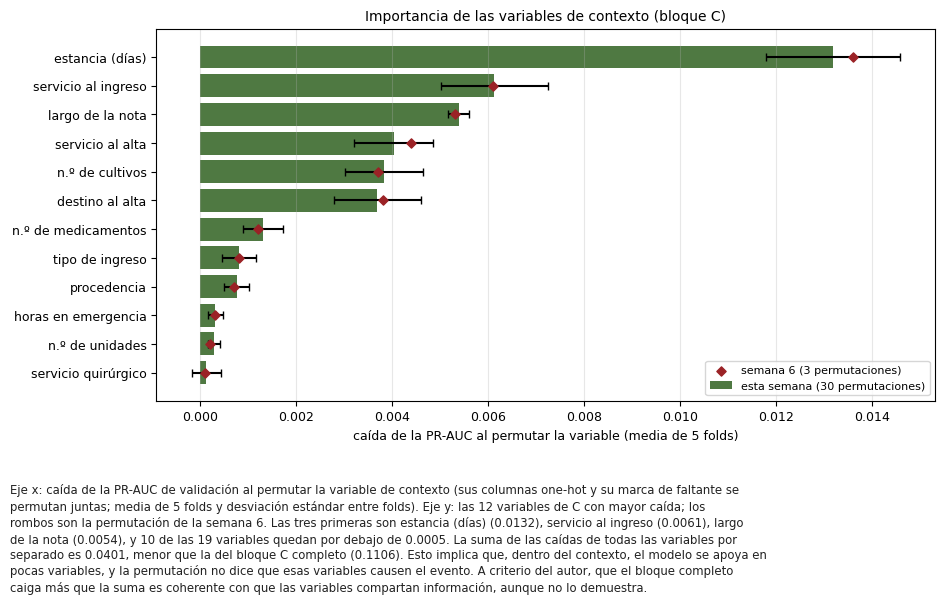

In [26]:
fig = figuras_imp.fig_contexto(R)
plt.show()

Fuente: elaboración propia a partir de `reportes/importancia_resultados.json`.

En la Figura 5 se observa, además, que la suma de las caídas de todas las variables por separado (0.0401) es menor que la caída del
bloque C completo (0.1106). A criterio del autor, esto es coherente con que las variables de contexto también compartan
información entre sí, aunque no lo demuestra. Asimismo, el peso de la estancia y del servicio refuerza la
duda, planteada desde la semana 5, de si el modelo reconoce en parte el tipo de paciente; esa duda corresponde a HE1 y no se resuelve aquí.

### 2.6 Coeficientes de los términos y su estabilidad entre *folds*

La Tabla 12 presenta la estabilidad de los términos de mayor coeficiente entre los 5 *folds*, medida sin mostrar ningún término. Se informan la
correlación de rangos de Spearman de todos los coeficientes entre cada par de *folds* y el número de términos que están en el *top*
20 de los 5 *folds*. También se informa el índice de Jaccard medio entre los *top* de cada par de *folds*, que vale 1 si los dos
*top* son iguales y 0 si no comparten ningún término.

In [27]:
filas = {}
for blq, e in R["estabilidad_coeficientes"].items():
    for signo in ("positivo", "negativo"):
        filas[f"{blq} · {signo}"] = {"Spearman medio (todos los términos)": e["spearman_coeficientes"]["media"],
                                     f"en el top {e[signo]['top']} de los 5 folds": e[signo]["en_los_5_folds"],
                                     "en al menos 3 folds": e[signo]["en_al_menos_3_folds"],
                                     "términos distintos en los 5 top": e[signo]["terminos_distintos_en_los_top"],
                                     "Jaccard medio": e[signo]["jaccard_medio_entre_pares"]}
t5 = pd.DataFrame(filas).T
t5.index.name = "Tabla 12. Bloque y signo del coeficiente"
t5

,Spearman medio (todos los términos),en el top 20 de los 5 folds,en al menos 3 folds,términos distintos en los 5 top,Jaccard medio
Tabla 12. Bloque y signo del coeficiente,,,,,
A · positivo,0.7769,15.0,21.0,25.0,0.7813
A · negativo,0.7769,3.0,12.0,55.0,0.2548
B · positivo,0.7696,16.0,19.0,27.0,0.7880
B · negativo,0.7696,2.0,10.0,59.0,0.2109


Fuente: elaboración propia a partir de `reportes/importancia_resultados.json`.

Como se aprecia en la Tabla 12, la correlación de rangos de los coeficientes entre *folds* es de 0.78 en
las palabras y de 0.77 en los bigramas. De los 20 términos de mayor coeficiente
positivo, 15 palabras y 16 bigramas se repiten en los 5 *folds*, con un Jaccard
medio de 0.78 y 0.79. En cambio, del lado negativo
solo se repiten 3 y 2, con un Jaccard de
0.25 y 0.21. De esta manera, los términos que empujan
hacia evento son estables, mientras que los que empujan hacia sin evento cambian de un *fold* a otro.

La Tabla 13 presenta el resultado del filtro de privacidad sobre los términos candidatos. Un término puede incumplir más de un criterio, por lo
cual la suma por criterio puede superar al total de excluidos.

In [28]:
fp = R["filtro_privacidad"]
t6 = pd.Series({"términos candidatos": fp["candidatos"], **{f"incumple: {k.replace(' %', '%')}": v for k, v in fp["por_motivo"].items()},
                "excluidos (al menos un criterio)": fp["excluidos"], "publicables": fp["publicables"]}, name="términos").to_frame()
t6.index.name = "Tabla 13. Filtro de privacidad"
display(t6)
print("Términos publicados en reportes/importancia_terminos.csv:", len(T), "· todos con al menos", T.pacientes_train.min(), "pacientes y",
      f"el {T.pct_notas_train.min():g}% de las epicrisis de train")

,términos
Tabla 13. Filtro de privacidad,
términos candidatos,409
incumple: dígitos o símbolos,33
incumple: menos de 100 pacientes,0
incumple: menos del 1% de las epicrisis,36
incumple: posible nombre propio,45
excluidos (al menos un criterio),109
publicables,300


Términos publicados en reportes/importancia_terminos.csv: 60 · todos con al menos 432 pacientes y el 1% de las epicrisis de train


Fuente: elaboración propia a partir de `reportes/importancia_resultados.json` y `reportes/importancia_terminos.csv`.

Como se aprecia en la Tabla 13, de 409 términos candidatos el filtro excluyó 109 y dejó 300. Los
motivos más frecuentes fueron el posible nombre propio (45), la frecuencia menor del
1% de las epicrisis (36) y la presencia de
dígitos o símbolos (33). La Figura 6 presenta los 15 términos publicables de mayor
coeficiente medio de cada signo y bloque.

Figura 6. Términos de mayor coeficiente positivo y negativo que pasaron el filtro de privacidad

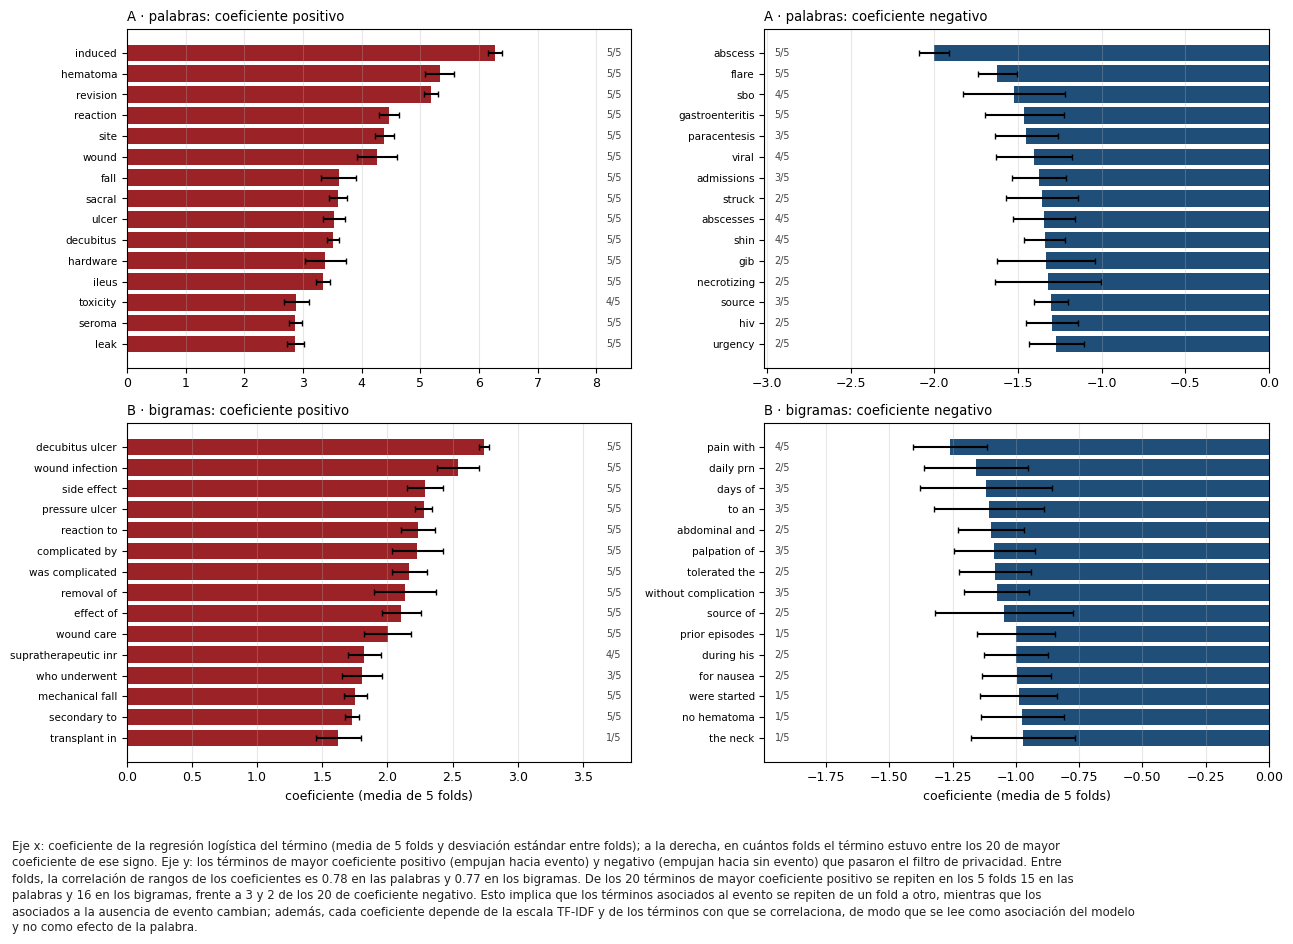

In [29]:
fig = figuras_imp.fig_terminos(R, T)
plt.show()

Fuente: elaboración propia a partir de `reportes/importancia_terminos.csv` y `reportes/importancia_resultados.json`.

En la Figura 6 se observa que los términos de coeficiente positivo con mayor peso en las palabras son *induced*, *hematoma*, *revision*, *reaction*, *site*, *wound*, y en los bigramas,
*decubitus ulcer*, *wound infection*, *side effect*, *pressure ulcer*. Los 10 términos citados estuvieron
en el *top* 20 de los 5 *folds*. Además, *fall* (caída) ocupa el puesto 7 de las palabras y *mechanical fall* el puesto
13 de los bigramas. A criterio del autor, estos términos describen
complicaciones de procedimientos, lesiones por presión, caídas y efectos adversos de medicamentos, es decir, las mismas familias de códigos
con que se construyó la etiqueta.

Por su parte, los de coeficiente negativo con mayor peso son *abscess*, *flare*, *sbo*, *gastroenteritis*, *paracentesis*, *viral* en las palabras y *pain with*, *daily prn*, *days of*, *to an* en los bigramas. A
criterio del autor, las palabras aluden a motivos de ingreso médicos, como infecciones u obstrucciones. Varias de ellas están en el *top* de
4 o 5 *folds*, pero el conjunto de términos negativos cambia de un *fold* a otro (Jaccard de 0.25
y 0.21). Esa inestabilidad del conjunto es coherente con que el modelo reconozca la ausencia
de evento por el tipo de ingreso y no por un grupo fijo de términos. Esta lectura es una interpretación y no un
hallazgo, dado que los coeficientes no miden efectos.

In [30]:
lista = pd.concat([T[(T.bloque == "A") & (T.signo == "positivo")].head(6), T[(T.bloque == "B") & (T.signo == "positivo")].head(4)])
print("De los", len(lista), "términos positivos citados en el texto, en el top de los 5 folds:", int((lista.folds_en_top == 5).sum()))
print("Puesto de fall entre las palabras positivas:", int(T[(T.bloque == "A") & (T.termino == "fall")].puesto.iloc[0]),
      "· de mechanical fall entre los bigramas positivos:", int(T[(T.bloque == "B") & (T.termino == "mechanical fall")].puesto.iloc[0]))
for (blq, signo), g in T.groupby(["bloque", "signo"], sort=False):
    print(f"{blq} · {signo}:", ", ".join(f"{r.termino} ({r.coef_media:+.2f}, top en {r.folds_en_top}/5)" for r in g.head(6).itertuples()))

De los 10 términos positivos citados en el texto, en el top de los 5 folds: 10
Puesto de fall entre las palabras positivas: 7 · de mechanical fall entre los bigramas positivos: 13
A · positivo: induced (+6.27, top en 5/5), hematoma (+5.33, top en 5/5), revision (+5.19, top en 5/5), reaction (+4.47, top en 5/5), site (+4.39, top en 5/5), wound (+4.26, top en 5/5)
A · negativo: abscess (-2.00, top en 5/5), flare (-1.62, top en 5/5), sbo (-1.52, top en 4/5), gastroenteritis (-1.46, top en 5/5), paracentesis (-1.45, top en 3/5), viral (-1.40, top en 4/5)
B · positivo: decubitus ulcer (+2.74, top en 5/5), wound infection (+2.54, top en 5/5), side effect (+2.29, top en 5/5), pressure ulcer (+2.28, top en 5/5), reaction to (+2.23, top en 5/5), complicated by (+2.23, top en 5/5)
B · negativo: pain with (-1.26, top en 4/5), daily prn (-1.16, top en 2/5), days of (-1.12, top en 3/5), to an (-1.11, top en 3/5), abdominal and (-1.10, top en 2/5), palpation of (-1.09, top en 3/5)


### 2.7 Tiempo de cómputo

La Tabla 14 presenta el tiempo de cada etapa, en minutos, medido por el propio *script*.

In [31]:
NOMBRE = {"modelos": "carga de la caché y ajuste de la regresión (5 folds)", "nombres_y_equivalencia": "vocabulario y control de la caché",
          "permutaciones": "permutaciones", "filtro_privacidad": "filtro de privacidad", "total": "total"}
t7 = pd.Series(R["tiempos_segundos"]).div(60).round(1).rename(NOMBRE).rename("minutos").to_frame()
t7.index.name = "Tabla 14. Etapa"
t7

,minutos
Tabla 14. Etapa,
carga de la caché y ajuste de la regresión (5 folds),5.6
vocabulario y control de la caché,10.8
permutaciones,0.2
filtro de privacidad,3.5
total,20.3


Fuente: elaboración propia a partir de `reportes/importancia_resultados.json`.

Como se aprecia en la Tabla 14, el cálculo completo tomó 20.3 minutos, de modo que no fue
necesario reducir las 30 permutaciones. La mayor parte del tiempo se destinó a reconstruir el vocabulario de cada *fold* y
a comprobar la caché (10.8 minutos), mientras que las permutaciones tomaron
0.2 minutos, porque se calculan sobre el aporte de cada grupo al *logit*.

### 2.8 Conclusiones y siguiente paso

Una vez analizados los resultados, se concluye que el modelo vigente se apoya sobre todo en el texto de la epicrisis. La permutación conjunta
de palabras y bigramas reduce la PR-AUC en 0.2349, frente a 0.1106 del contexto, y el orden de los bloques se repite en
los 5 *folds*. Dentro del contexto pesan sobre todo estancia (días) y servicio al ingreso, y los términos que empujan
hacia evento son estables entre *folds*, a diferencia de los que empujan hacia sin evento.

Es preciso tomar en consideración que estas importancias describen el comportamiento del modelo entrenado y no relaciones causales, y que la
permutación de cada bloque por separado puede subestimar su peso si los bloques comparten información. Asimismo, ninguna cifra de esta parte usó la partición de
*test* ni se calculó por servicio, edad o largo de la nota, de modo que HE1 queda intacta para su evaluación.

Se recomienda, como siguiente paso del Sprint 3, evaluar HE1 con la comparación por servicio, grupo de edad y decil de largo prevista desde la
semana 5, y recalibrar las probabilidades a la prevalencia real. Para reproducir este análisis se ejecuta `python src/importancia_variables.py`,
el cual requiere la caché de conteos de `python src/experimentos_hp.py --solo-conteos`.

## 3. Equivalencia de los códigos CIE-10 con los eventos del Anexo N.º 02, validada por el autor

La tabla de la etiqueta asigna a cada código CIE-10 un evento del Anexo N.º 02 de la Directiva N.º 7-OGCyH-ESSALUD-2020, pero mezcla los
números oficiales del Anexo con números internos y reutiliza algunos. Por ejemplo, el 301 identifica en ella tanto el error en el
diagnóstico (Y65.8), que es su significado oficial, como una hemorragia postprocedimiento (T81.0). Por ello, se construyó una
equivalencia que establece el evento oficial de cada código.

La propuesta de equivalencia se construyó con reglas explícitas a partir del título oficial de cada código en la CIE-10 de la OMS
(versión 2019) o en la CIE-10-CM, con la que se codifica MIMIC-IV. El autor la validó código por código el 29 de octubre de 2026, en
un instrumento de validación que registra cada decisión con su fecha. Ese mismo día precisó el alcance de 20 de sus decisiones y
corrigió 3, lo cual consta en la columna `aclaracion_autor`.

In [32]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
leer = lambda n: json.loads((RAIZ / "reportes" / n).read_text(encoding="utf-8"))
W = pd.read_csv(RAIZ / "data" / "catalogos" / "anexo02_equivalencia_cie10_oficial.csv", dtype=str, keep_default_na=False)
U = W.drop_duplicates("codigo_cie10")
print("Filas de la tabla de la etiqueta:", len(W), "· códigos distintos:", len(U),
      "· validado por:", ", ".join(sorted(U.validado_por.unique())), "· fecha:", ", ".join(sorted(U.fecha_validacion.unique())))

Filas de la tabla de la etiqueta: 272 · códigos distintos: 223 · validado por: Carlos Pérez Pérez · fecha: 2026-10-29


La Tabla 15 presenta el resultado validado de los 223 códigos distintos de la tabla de la etiqueta y el número de eventos oficiales
distintos a los que quedaron asignados.

In [33]:
orden = ["con evento", "solo naturaleza", "sin equivalente", "no es evento adverso"]
t15 = pd.DataFrame({"códigos": U.estado_validado.value_counts().reindex(orden).astype(int)})
t15["eventos oficiales distintos"] = ""
t15.loc["con evento", "eventos oficiales distintos"] = U.loc[U.id_ev_validado != "", "id_ev_validado"].nunique()
t15.loc["total"] = [int(t15["códigos"].sum()), U.loc[U.id_ev_validado != "", "id_ev_validado"].nunique()]
t15.index.name = "Tabla 15. Resultado validado"
display(t15)

,códigos,eventos oficiales distintos
Tabla 15. Resultado validado,,
con evento,131,60
solo naturaleza,24,
sin equivalente,27,
no es evento adverso,41,
total,223,60


Fuente: elaboración propia a partir de `data/catalogos/anexo02_equivalencia_cie10_oficial.csv`.

Como se aprecia en la Tabla 15, de los 223 códigos distintos, 131 quedaron con un evento oficial, que suman 60 eventos distintos, 24
solo con la naturaleza, 27 sin equivalente y 41 marcados como no evento adverso. A criterio del autor, en los códigos con evento, si el
evento ocurrió durante la atención lo decide el contexto de la epicrisis y no el código.

La Tabla 16 presenta la decisión final del autor sobre cada código, cuántas de esas decisiones tienen una aclaración del 29 de octubre y
cuántas modifican la propuesta.

In [34]:
t16 = U.groupby("decision_autor").agg(**{"códigos": ("codigo_cie10", "size"),
                                         "con aclaración del 29 de octubre": ("aclaracion_autor", lambda s: int((s != "").sum())),
                                         "cambian la propuesta": ("cambia_la_propuesta", lambda s: int((s == "sí").sum()))})
t16 = t16.sort_values("códigos", ascending=False)
t16.loc["total"] = t16.sum()
t16.index.name = "Tabla 16. Decisión final del autor"
display(t16)
L = leer("negativas_liberadas_resumen.json")
print("Códigos marcados como no evento adverso:", L["codigos"])
print("Positivas que dependen solo de ellos:", L["positivas_que_dependen_solo_de_ellos"])
cat = pd.read_csv(RAIZ / "data" / "catalogos" / "anexo02_catalogo_231.csv", dtype=str, keep_default_na=False)
print("Eventos del catálogo:", len(cat), "· nombre de trabajo distinto del nombre oficial:", int((cat.nombre != cat.nombre_oficial).sum()))

,códigos,con aclaración del 29 de octubre,cambian la propuesta
Tabla 16. Decisión final del autor,,,
confirma la propuesta,135,0,0
no es evento adverso,41,0,29
sin equivalente,26,20,0
otro evento,16,0,16
vuelve a la propuesta,3,3,0
solo naturaleza,2,0,1
total,223,23,46


Códigos marcados como no evento adverso: {'no_es_evento_adverso': 41, 'en_estrato_A1_o_equivalencias': 0, 'en_estrato_A2': 32, 'sin_registros': 9}
Positivas que dependen solo de ellos: 0
Eventos del catálogo: 231 · nombre de trabajo distinto del nombre oficial: 72


Fuente: elaboración propia a partir de `data/catalogos/anexo02_equivalencia_cie10_oficial.csv`,
`reportes/negativas_liberadas_resumen.json` y `data/catalogos/anexo02_catalogo_231.csv`.

Como se aprecia en la Tabla 16, la validación dejó sin cambio 177 propuestas y modificó 46. Las 20 precisiones corresponden a códigos
que el autor había marcado como no evento adverso y que, según precisó, sí describen un evento de la atención, pero no indican cuál
evento del Anexo N.º 02, por lo que quedan sin equivalente. En los otros 3, el autor volvió a la propuesta.

La equivalencia no modifica la etiqueta del modelo. Ninguno de los 41 códigos marcados como no evento adverso pertenece al estrato A1
ni a sus equivalencias CIE-10-CM, que, junto con las cinco familias CIE-9, son las fuentes de las positivas, de modo que ninguna
positiva depende de ellos. Sin embargo, todos son del estrato A2, el cual excluye del sorteo de las negativas a las hospitalizaciones
que los tienen, y ese efecto se prueba en la parte 4.

Adicionalmente, el catálogo de los 231 eventos incorpora la columna `nombre_oficial`, la cual reproduce el nombre de cada evento según
la tabla del Anexo N.º 02 (páginas 30 a 38 del PDF), sin corregir su ortografía. La columna `nombre` conserva el nombre de trabajo del
proyecto, con el que el EDA enlaza las tablas, y difiere del oficial en 72 eventos.

## 4. Variante D3: negativas que libera la equivalencia validada

### 4.1 Motivo

La equivalencia que el autor validó el 29 de octubre de 2026 (ver la parte 3) marcó 41 códigos de la tabla de la etiqueta como no evento adverso.
Ninguno de ellos pertenece al estrato A1 ni a sus equivalencias CIE-10-CM, por lo que ninguna positiva depende de ellos. Sin embargo,
todos son del estrato A2, el cual excluye del sorteo de las negativas a toda hospitalización que tenga uno de sus códigos
(`src/preprocesado.py`, líneas 66 a 69), y 32 de ellos tienen hospitalizaciones registradas en las tablas de la etiqueta.

En consecuencia, retirar esos códigos de la etiqueta no cambia ninguna positiva, pero libera 16 189 hospitalizaciones, todas de la época
CIE-10 y con epicrisis, cuyos códigos A2 pertenecen todos a ese grupo. Frente a las 59 423 hospitalizaciones de esa época con epicrisis
que hoy pueden sortearse como negativas, las liberadas serían el 21.4% de las negativas de esa época en un nuevo sorteo.

Por decisión del autor, el cambio se probó como una variante nueva, D3, sin modificar D2. HE2 y HE3 siguen con D2, que es la variante con
la que se sorteó el lote de la revisión ciega.

In [35]:
R3, L, P = leer("d3_resultados.json"), leer("negativas_liberadas_resumen.json"), leer("d3_perfil_liberadas.json")
F = pd.read_csv(RAIZ / "reportes" / "d3_folds.csv")
print("Hospitalizaciones liberadas:", L["liberadas"]["hospitalizaciones"], "· por época:", L["liberadas"]["por_epoca"])
print("Marco de negativas de la época CIE-10 con epicrisis:", L["proporcion"]["marco_epoca10_con_epicrisis"],
      "· proporción esperada en un nuevo sorteo:", L["proporcion"]["proporcion_entre_negativas_epoca10"])
print("Liberadas sin etiqueta dudosa:", R3["liberadas"])

Hospitalizaciones liberadas: 16189 · por época: {'10': 16189}
Marco de negativas de la época CIE-10 con epicrisis: 59423 · proporción esperada en un nuevo sorteo: 0.214106
Liberadas sin etiqueta dudosa: {'sin_etiqueta_dudosa_train': 10399, 'sin_etiqueta_dudosa_test': 2539, 'proporcion_esperada_entre_negativas_cie10': 0.1924, 'dudosas_en_el_corpus_cie10': 0.0861, 'dudosas_en_las_liberadas': 0.2008}


### 4.2 Diseño, fijado antes de correr

Antes de correr se fijó la forma de calcular cada cantidad. Las cifras que en esta lista se presentan como de la corrida salen de ella y
no formaban parte del diseño.

- Modelo: el vigente, A+B+C con la configuración que confirmó la búsqueda de hiperparámetros, sin cambios.
- D2: las mismas filas de entrenamiento de la semana 6 (en la corrida, 39 198 por *fold* en promedio).
- D3: las filas de D2 y el mismo número de ellas, pero en cada entrenamiento se reemplaza al azar, por liberadas, la proporción esperada
  de las negativas de la época CIE-10. En la corrida fueron entre 1 043 y 1 059 filas por *fold*, el 2.7% del entrenamiento, y 1 313 de
  48 998 en el entrenamiento final.
- Proporción esperada: la que tendrían las liberadas sin etiqueta dudosa entre las negativas de la época CIE-10 sin etiqueta dudosa,
  porque ni D2 ni D3 entrenan con las dudosas (códigos causales fuera de la tabla). En la corrida, el 20.1% de las liberadas eran
  dudosas, frente al 8.6% de las negativas de esa época en el corpus, y la proporción fue 19.2%.
- Tasa de dudosas del corpus: se tomó de *train* y *test* juntos. Según un cálculo aparte con los datos locales de MIMIC-IV, que no queda
  en los archivos versionados, solo con *train* (8.3%) la proporción habría sido 0.1919 y no 0.1924, con unas 3 filas menos por *fold*.
- Datos de las liberadas: la epicrisis se recupera y se filtra como en `src/preprocesado.py` (texto de más de 100 caracteres), y las
  variables de dominio y las marcas de etiqueta dudosa se calculan con las mismas funciones del corpus, en cachés aparte.
- Partición: los 5 *folds* de la semana 6 (`StratifiedGroupKFold` por paciente, semilla 42). La liberada de un paciente del corpus va a la
  misma partición y al mismo *fold* que ese paciente; la de un paciente nuevo va a *test* con probabilidad 0.20 (`test_size`) y, en
  *train*, a un *fold* al azar, siempre por paciente.
- Evaluaciones, las mismas para D2 y D3:
  1) común: las filas de validación (o de *test*) sin etiqueta dudosa, las mismas de la semana 6;
  2) ampliada: las de la común más liberadas del mismo *fold* (o del *test*), en la proporción esperada entre las negativas de la época
     CIE-10, con el mismo sorteo para las dos variantes (en la corrida, entre 315 y 334 por *fold* y 409 en *test*);
  3) liberadas marcadas: proporción de las liberadas del *fold* (o del *test*) con probabilidad de 0.5 o más, frente a la de las
     negativas de la época CIE-10 de la evaluación común, que en adelante se denominan negativas comunes.
- Regla: D3 se considera mejor que D2 si su PR-AUC en la evaluación ampliada supera a la de D2 en al menos 4 de los 5 *folds* y la
  diferencia media supera una desviación estándar de las diferencias por *fold*. Es la misma forma de la regla de la parte 1.
- Prerregistro: la regla se escribió en el encabezado de `src/experimentos_d3.py` antes de la corrida corta de control (`--prueba`) y de
  la corrida completa, y no se modificó después. Sin embargo, el *script* no tiene un *commit* anterior a la corrida, y el registro de la
  corrida corta se borró antes de la corrida completa. Por ello, el repositorio no contiene una prueba con fecha de ese orden.
- Cambios posteriores: después de la corrida completa solo se corrigieron, en `src/experimentos_d3.py`, el comentario del modo
  `--prueba` y una importación sin uso, sin cambiar ningún cálculo.

La celda siguiente imprime, a partir de los archivos de resultados, las cifras que cita esta lista y las que se citan más adelante.

In [36]:
d2r, d3r = F[F.variante == "D2"], F[F.variante == "D3"]
print("Filas de entrenamiento de D2 por fold (promedio):", round(d2r.filas_entrenamiento.mean(), 1))
fr = d3r.liberadas_en_entrenamiento / d3r.filas_entrenamiento
print("Liberadas en el entrenamiento de D3 por fold:", d3r.liberadas_en_entrenamiento.min(), "a", d3r.liberadas_en_entrenamiento.max(),
      "· proporción del entrenamiento:", round(fr.min(), 4), "a", round(fr.max(), 4))
print("Entrenamiento final de D3:", R3["test"]["D3"]["liberadas_en_entrenamiento"], "liberadas de", R3["test"]["D3"]["filas_entrenamiento"], "filas")
print("Liberadas agregadas a la evaluación ampliada por fold:", d2r.liberadas_en_ampliada.min(), "a", d2r.liberadas_en_ampliada.max(),
      "· en test:", R3["test"]["D2"]["ampliada"]["liberadas_agregadas"])
print("Mejora de D2 sobre D0 en la semana 6 (validación cruzada):", leer("datos_resultados.json")["cv"]["D2"]["dif_pr_auc_comun_vs_D0"])
cy = leer("eda_resumen.json")["correlaciones_spearman"]["con_y"]
print("Correlación de Spearman con la etiqueta (EDA de la semana 4):", {k: cy[k] for k in ("estancia (días)", "largo (caracteres)")})
dur = [l for l in (RAIZ / "logs" / "metrics_d3.txt").read_text(encoding="utf-8").splitlines() if l.startswith("duración")][0]
print("Duración de la corrida de D3:", dur.split(":", 1)[1].strip(), "·", round(int(dur.split()[1]) / 60, 1), "minutos")

Filas de entrenamiento de D2 por fold (promedio): 39198.4
Liberadas en el entrenamiento de D3 por fold: 1043 a 1059 · proporción del entrenamiento: 0.0265 a 0.0272
Entrenamiento final de D3: 1313 liberadas de 48998 filas
Liberadas agregadas a la evaluación ampliada por fold: 315 a 334 · en test: 409
Mejora de D2 sobre D0 en la semana 6 (validación cruzada): {'media': 0.0103, 'std': 0.0023, 'folds_mejor_que_D0': 5}
Correlación de Spearman con la etiqueta (EDA de la semana 4): {'estancia (días)': 0.3063, 'largo (caracteres)': 0.1823}
Duración de la corrida de D3: 4956 s · 82.6 minutos


### 4.3 Control de reproducción

In [37]:
D6 = pd.read_csv(RAIZ / "reportes" / "datos_folds.csv")
d2 = F[F.variante == "D2"].set_index("fold")
s6 = D6[D6.variante == "D2"].set_index("fold")
print("Diferencia máxima de la PR-AUC común de D2 frente a la semana 6:", round(float((d2.pr_auc_comun - s6.pr_auc_comun).abs().max()), 6))
print("Mismo número de filas de entrenamiento por fold:", bool((d2.filas_entrenamiento == s6.filas_entrenamiento).all()))
te6 = leer("datos_resultados.json")["test"]["D2"]["comun"]
print("Test de D2, semana 6:", te6["pr_auc"], te6["pr_auc_ic95_pacientes"], "· esta corrida:",
      R3["test"]["D2"]["comun"]["pr_auc"], R3["test"]["D2"]["comun"]["pr_auc_ic95_pacientes"])

Diferencia máxima de la PR-AUC común de D2 frente a la semana 6: 0.0
Mismo número de filas de entrenamiento por fold: True
Test de D2, semana 6: 0.8671 [0.8589, 0.8749] · esta corrida: 0.8671 [0.8589, 0.8749]


Como se aprecia en la salida anterior, D2 reprodujo la PR-AUC común de la semana 6 en los 5 *folds*, con el mismo número de
filas de entrenamiento y sin diferencias hasta el sexto decimal. En *test* obtuvo 0.8671 (IC 95%: 0.8589 a 0.8749), igual que en la semana 6.

### 4.4 Resultados

La Tabla 17 presenta la PR-AUC por *fold* de D2 y D3 en las dos evaluaciones, junto con las diferencias, que se calculan con seis
decimales.

In [38]:
d3 = F[F.variante == "D3"].set_index("fold")
t17 = pd.DataFrame({"D2 común": d2.pr_auc_comun, "D3 común": d3.pr_auc_comun, "diferencia común": d3.pr_auc_comun - d2.pr_auc_comun,
                    "D2 ampliada": d2.pr_auc_ampliada, "D3 ampliada": d3.pr_auc_ampliada,
                    "diferencia ampliada": d3.pr_auc_ampliada - d2.pr_auc_ampliada})
t17.loc["media"] = t17.mean()
t17.index.name = "Tabla 17. PR-AUC por fold"
display(t17.round(4))
dc, da = (d3.pr_auc_comun - d2.pr_auc_comun), (d3.pr_auc_ampliada - d2.pr_auc_ampliada)
print(f"Diferencia común: {dc.mean():+.4f} ± {dc.std(ddof=1):.4f} · folds en que D3 supera a D2: {int((dc > 0).sum())} de 5")
print(f"Diferencia ampliada: {da.mean():+.6f} ± {da.std(ddof=1):.6f} · folds en que D3 supera a D2: {int((da > 0).sum())} de 5")
print("Regla cumplida (registrada por el script):", R3["regla_cumplida"], "· sin redondear:", bool((da > 0).sum() >= 4 and da.mean() > da.std(ddof=1)))

,D2 común,D3 común,diferencia común,D2 ampliada,D3 ampliada,diferencia ampliada
Tabla 17. PR-AUC por fold,,,,,,
1,0.8567,0.8555,-0.0012,0.8405,0.8434,0.0028
2,0.8527,0.8503,-0.0025,0.8356,0.8364,0.0008
3,0.8467,0.8470,0.0003,0.8289,0.8334,0.0044
4,0.8542,0.8536,-0.0006,0.8393,0.8417,0.0024
5,0.8566,0.8544,-0.0022,0.8409,0.8415,0.0006
media,0.8534,0.8522,-0.0012,0.8370,0.8393,0.0022


Diferencia común: -0.0012 ± 0.0011 · folds en que D3 supera a D2: 1 de 5
Diferencia ampliada: +0.002207 ± 0.001578 · folds en que D3 supera a D2: 5 de 5
Regla cumplida (registrada por el script): True · sin redondear: True


Fuente: elaboración propia a partir de `reportes/d3_folds.csv` y `reportes/d3_resultados.json`. El *script* evaluó la regla con la
media y la desviación redondeadas a cuatro decimales, y sin redondear (0.002207 y 0.001578) el resultado es el mismo.

Como se aprecia en la Tabla 17, D3 supera a D2 en la evaluación ampliada en los 5 *folds*, con una diferencia media de +0.0022 y una
desviación estándar de 0.0016, de modo que se cumplen las dos condiciones de la regla. En la evaluación común, en cambio, D3 queda por
debajo de D2 en 4 de los 5 *folds* (-0.0012 ± 0.0011). Ambas diferencias son pequeñas frente a la mejora de D2 sobre D0 en la semana 6
(+0.0103).

La Tabla 18 presenta la proporción de hospitalizaciones que cada variante marca como evento, con probabilidad de 0.5 o más.

In [39]:
cv, te = R3["cv"], R3["test"]
t18 = pd.DataFrame({v: {"liberadas, validación cruzada": cv[v]["marcadas_liberadas"]["media"],
                        "negativas comunes, validación cruzada": cv[v]["marcadas_negativas_cie10_comun"]["media"],
                        "liberadas, test": te[v]["marcadas_liberadas"],
                        "negativas comunes, test": te[v]["marcadas_negativas_cie10_comun"]} for v in ("D2", "D3")}).T
t18.index.name = "Tabla 18. Variante"
display(t18)
print("Liberadas evaluadas: train", R3["liberadas"]["sin_etiqueta_dudosa_train"], "· test", te["D2"]["liberadas_evaluadas"])
print("Negativas comunes marcadas, D3 menos D2 por fold:", (d3.marcadas_negativas_cie10_comun - d2.marcadas_negativas_cie10_comun).round(4).tolist())

,"liberadas, validación cruzada","negativas comunes, validación cruzada","liberadas, test","negativas comunes, test"
Tabla 18. Variante,,,,
D2,0.4261,0.1873,0.4179,0.1725
D3,0.3461,0.1775,0.3403,0.1655


Liberadas evaluadas: train 10399 · test 2539
Negativas comunes marcadas, D3 menos D2 por fold: [-0.0122, -0.005, -0.0092, -0.0118, -0.011]


Fuente: elaboración propia a partir de `reportes/d3_resultados.json` y `reportes/d3_folds.csv`. En validación cruzada es la media de
los 5 *folds*, sobre 10 399 liberadas de *train*; en *test*, sobre 2 539 liberadas.

Como se aprecia en la Tabla 18, D2 marca como evento a cuatro de cada diez liberadas (0.4261 en validación cruzada y 0.4179 en *test*),
más del doble que a las negativas comunes (0.1873 y 0.1725). D3, que entrenó con liberadas como negativas, baja esa proporción a 0.3461 y
0.3403. Asimismo, la proporción de las negativas comunes baja en los 5 *folds*, de 0.1873 a 0.1775 en promedio, y en *test* de 0.1725 a
0.1655.

La Tabla 19 presenta las liberadas de *test* marcadas como evento según los cinco códigos A2 más frecuentes entre las liberadas, con las
descripciones de la tabla de la etiqueta, a las que se agregaron tildes y puntuación.

In [40]:
DESCRIPCION = {"N17.0": "Insuficiencia renal aguda con necrosis tubular",
               "B95": "Estreptococos y estafilococos como causa de enfermedades clasificadas en otros capítulos",
               "J96.0": "Insuficiencia respiratoria aguda", "N17.9": "Insuficiencia renal aguda no especificada",
               "S22": "Fractura de costilla, esternón y columna torácica"}
pc2, pc3 = te["D2"]["marcadas_liberadas_por_codigo"], te["D3"]["marcadas_liberadas_por_codigo"]
t19 = pd.DataFrame({c: {"descripción": DESCRIPCION[c], "liberadas en test": pc2[c]["n"], "D2": pc2[c]["marcadas"], "D3": pc3[c]["marcadas"]}
                    for c in pc2}).T.sort_values("D2", ascending=False)
t19.index.name = "Tabla 19. Código"
display(t19)
print("Cinco códigos más frecuentes entre las 16 189 liberadas:", dict(list(L["liberadas"]["por_codigo"].items())[:5]))

,descripción,liberadas en test,D2,D3
Tabla 19. Código,,,,
N17.0,Insuficiencia renal aguda con necrosis tubular,77,0.7532,0.6494
B95,Estreptococos y estafilococos como causa de en...,234,0.7051,0.6239
J96.0,Insuficiencia respiratoria aguda,303,0.5446,0.4653
N17.9,Insuficiencia renal aguda no especificada,1517,0.4311,0.3276
S22,"Fractura de costilla, esternón y columna torácica",99,0.1919,0.1818


Cinco códigos más frecuentes entre las 16 189 liberadas: {'N17.9': 9371, 'J96.0': 1910, 'B95': 1427, 'S22': 886, 'N17.0': 587}


Fuente: elaboración propia a partir de `reportes/d3_resultados.json` y `reportes/negativas_liberadas_resumen.json`, con las
descripciones de `data/catalogos/anexo02_equivalencia_cie10_oficial.csv`, a las que se agregaron tildes y puntuación. Una hospitalización
puede tener más de uno de estos códigos.

Como se aprecia en la Tabla 19, la proporción de marcadas cambia mucho según el código. Con D2 es mayor en la insuficiencia renal aguda
con necrosis tubular (0.7532) y en los estreptococos y estafilococos como causa de enfermedad (0.7051), mientras que en las fracturas de
costilla, esternón y columna torácica (0.1919) queda cerca de la de las negativas comunes.

Figura 7. PR-AUC por *fold* y hospitalizaciones de *test* marcadas como evento

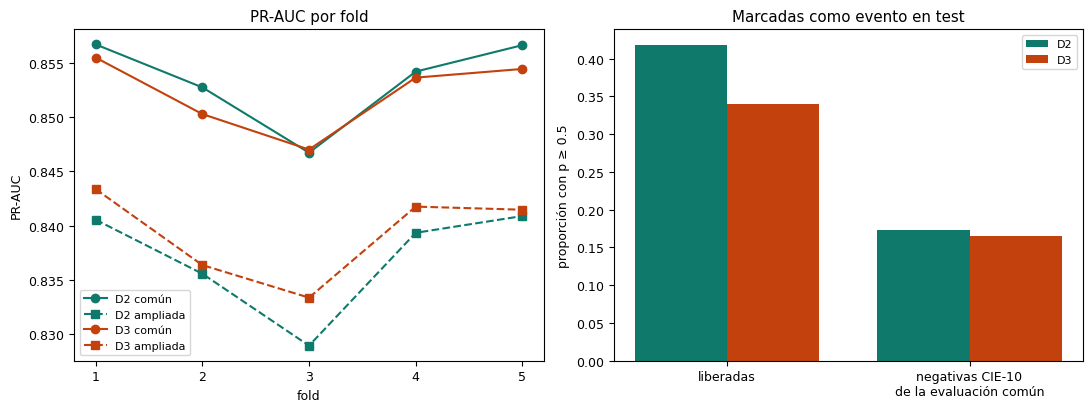

In [41]:
colores = {"D2": "#0F7A6B", "D3": "#C2410C"}
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for v, g in F.groupby("variante", sort=False):
    ax[0].plot(g.fold, g.pr_auc_comun, "o-", color=colores[v], label=f"{v} común")
    ax[0].plot(g.fold, g.pr_auc_ampliada, "s--", color=colores[v], label=f"{v} ampliada")
ax[0].set(xlabel="fold", ylabel="PR-AUC", title="PR-AUC por fold", xticks=range(1, 6))
ax[0].legend(fontsize=8)
x = np.arange(2)
for i, v in enumerate(("D2", "D3")):
    ax[1].bar(x + (i - 0.5) * 0.38, [te[v]["marcadas_liberadas"], te[v]["marcadas_negativas_cie10_comun"]], 0.38, color=colores[v], label=v)
ax[1].set(xticks=x, xticklabels=["liberadas", "negativas CIE-10\nde la evaluación común"], ylabel="proporción con p ≥ 0.5",
          title="Marcadas como evento en test")
ax[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

Fuente: elaboración propia a partir de `reportes/d3_folds.csv` y `reportes/d3_resultados.json`, con el mismo dibujo de
`reportes/figuras/fig_d3_resultados.png`.

En el gráfico izquierdo de la Figura 7, el eje x es el *fold* y el eje y la PR-AUC, con líneas continuas para la evaluación común y
discontinuas para la ampliada. En el derecho, cada barra es la proporción de hospitalizaciones de *test* con probabilidad de 0.5 o más, y
la mayor diferencia entre D2 y D3 se observa en las liberadas.

### 4.5 Medición única en *test*

La Tabla 20 presenta la medición única en *test* de D2 y D3, con el intervalo de confianza de la evaluación común calculado al
remuestrear pacientes 200 veces.

In [42]:
f4 = lambda x: f"{x:.4f}"      # cuatro decimales, como en el resto de las tablas
t20 = pd.DataFrame({v: {"PR-AUC común": f4(te[v]["comun"]["pr_auc"]),
                        "IC 95%": f'{te[v]["comun"]["pr_auc_ic95_pacientes"][0]:.4f} a {te[v]["comun"]["pr_auc_ic95_pacientes"][1]:.4f}',
                        "PR-AUC ampliada": f4(te[v]["ampliada"]["pr_auc"]), "ROC-AUC común": f4(te[v]["comun"]["roc_auc"]),
                        "sensibilidad": f4(te[v]["comun"]["recall"]), "especificidad común": f4(te[v]["comun"]["especificidad"]),
                        "especificidad ampliada": f4(te[v]["ampliada"]["especificidad"])} for v in ("D2", "D3")}).T
t20.index.name = "Tabla 20. Variante"
display(t20)
print("Liberadas agregadas a la evaluación ampliada de test:", te["D2"]["ampliada"]["liberadas_agregadas"])

,PR-AUC común,IC 95%,PR-AUC ampliada,ROC-AUC común,sensibilidad,especificidad común,especificidad ampliada
Tabla 20. Variante,,,,,,,
D2,0.8671,0.8589 a 0.8749,0.8518,0.8706,0.7689,0.8038,0.7892
D3,0.8652,0.8571 a 0.8735,0.8533,0.8695,0.7634,0.8030,0.7935


Liberadas agregadas a la evaluación ampliada de test: 409


Fuente: elaboración propia a partir de `reportes/d3_resultados.json`. La sensibilidad es la misma en las dos evaluaciones,
porque la ampliada solo agrega negativas.

Como se aprecia en la Tabla 20, el *test* repite el orden de la validación cruzada, ya que D3 queda por encima en la evaluación ampliada
(0.8533 frente a 0.8518) y por debajo en la común (0.8652 frente a 0.8671). Los intervalos de confianza de la evaluación común se solapan.

### 4.6 Qué significan estos resultados

Es preciso tomar en consideración que la evaluación ampliada cuenta a las liberadas como negativas, que es justamente el supuesto con el
que se entrena D3. Por ello, la mejora de D3 en esa evaluación muestra que aprendió a tratar a las liberadas como negativas, pero no
demuestra que lo sean.

Por otra parte, que D2 marque como evento a más del doble de liberadas que de negativas comunes indica que, para el modelo, las
liberadas se parecen más a las positivas que las demás negativas. Hay al menos dos explicaciones, y el experimento no permite distinguir
entre ellas. La primera es que en parte de ellas haya un evento de la atención que la etiqueta no registra con un código de causa
explícita, y la segunda, que el modelo responda a la gravedad del cuadro clínico y no a un evento.

La Tabla 21 presenta el perfil de las liberadas frente a las negativas y las positivas de la época CIE-10 del corpus, con el número de
hospitalizaciones, las medianas y la proporción con paso por UCI, sin entrenar ningún modelo.

In [43]:
NOMBRE = {"negativas_epoca10_corpus": "negativas de la época CIE-10", "liberadas": "liberadas",
          "positivas_epoca10_corpus": "positivas de la época CIE-10"}
t21 = pd.DataFrame.from_dict({NOMBRE[g]: {"hospitalizaciones": p["hospitalizaciones"],
                                           "largo de la epicrisis (caracteres)": p["largo_epicrisis_caracteres"]["mediana"],
                                           "estancia (días)": p["estancia_dias"]["mediana"], "edad (años)": p["edad"]["mediana"],
                                           "medicamentos distintos": p["medicamentos_distintos"]["mediana"],
                                           "proporción con paso por UCI": p["proporcion_con_uci"]}
                               for g, p in ((k, P["grupos"][k]) for k in NOMBRE)}, orient="index")
t21 = t21.apply(lambda s: s.astype(int) if (s % 1 == 0).all() else s)      # las medianas enteras se muestran sin decimales
t21.index.name = "Tabla 21. Grupo"
display(t21)

,hospitalizaciones,largo de la epicrisis (caracteres),estancia (días),edad (años),medicamentos distintos,proporción con paso por UCI
Tabla 21. Grupo,,,,,,
negativas de la época CIE-10,8540,9524,2.84,61,18,0.1341
liberadas,12938,11692,4.44,67,24,0.2468
positivas de la época CIE-10,9051,12393,6.47,66,31,0.3201


Fuente: elaboración propia a partir de `reportes/d3_perfil_liberadas.json`. Los tres grupos van sin etiqueta dudosa, con *train*
y *test* juntos, como en el EDA de la semana 4.

Como se aprecia en la Tabla 21, las liberadas quedan entre las negativas y las positivas de la época CIE-10 en el largo de la epicrisis,
la estancia, los medicamentos y el paso por UCI, y tienen la mayor edad mediana (67 años). La estancia y el largo de la nota son dos de
las tres variables de contexto de mayor peso del modelo (Tabla 11), por lo que este perfil es coherente con la segunda explicación. Sin
embargo, en el corpus la etiqueta también se asocia con la estancia y con el largo de la nota (correlaciones de Spearman de 0.306 y 0.182
según el EDA de la semana 4), de modo que el perfil tampoco permite elegir entre ellas.

En consecuencia, para saber cuántas liberadas son negativas verdaderas sería necesario leer la epicrisis de una muestra de ellas, como en
la revisión ciega. Mientras esa revisión no se haga, la diferencia entre D2 y D3 depende de un supuesto sobre la etiqueta que este
experimento no puede comprobar.

### 4.7 Decisión

- Por la regla fijada antes de la corrida, D3 se considera mejor que D2 en la evaluación ampliada (+0.0022 ± 0.0016, 5 de 5 *folds*). Esa
  evaluación supone que las liberadas son negativas verdaderas, y en la evaluación común D3 queda por debajo de D2 (-0.0012 ± 0.0011, 4
  de 5 *folds*).
- Por decisión del autor, HE2 y HE3 siguen con D2, que es la variante con la que se sorteó el lote de la revisión ciega.
- La regla no establecía si D3 debía reemplazar a D2 como referencia. Por decisión del autor del 29 de octubre de 2026, D2 se mantiene como
  referencia de los siguientes experimentos del Sprint 3, y D3 queda documentada como variante.

Para reproducir esta parte se ejecutan, en este orden, `python src/negativas_liberadas.py`, `python src/experimentos_d3.py` y
`python src/perfil_liberadas.py`; el segundo tomó 82.6 minutos en CPU.

## 5. Conclusiones de la semana 7

Una vez analizados los resultados, se concluye que la configuración vigente, es decir, D2 con A+B+C, C de 1 y 20 000 palabras y 20 000
bigramas, se mantiene como referencia del Sprint 3. Ninguna de las 25 configuraciones de la búsqueda la superó, y la candidata quedó por
debajo en los 5 *folds* de la confirmación.

Asimismo, el modelo se apoya sobre todo en el texto de la epicrisis, dado que la permutación conjunta de palabras y bigramas reduce la
PR-AUC en 0.2349, frente a 0.1106 del contexto. Dentro del contexto pesan sobre todo la estancia y el servicio al ingreso, lo cual deja
abierta la pregunta de HE1 sobre el tipo de paciente.

Por otra parte, la equivalencia validada por el autor asigna 131 de los 223 códigos a 60 eventos oficiales del Anexo N.º 02 y no modifica
la etiqueta del modelo. La variante D3 cumple la regla fijada en la evaluación ampliada (+0.0022), pero queda por debajo en la común
(-0.0012), y el modelo vigente marca como evento al 42.6% de las liberadas, frente al 18.7% de las negativas comunes. Por decisión del
autor, D2 se mantiene como referencia, también para HE2 y HE3, y D3 queda documentada como variante.

Es preciso tomar en consideración que la PR-AUC mide la concordancia del modelo con la etiqueta construida a partir de los códigos de
diagnóstico, y no con la presencia de eventos adversos reales. Con la prevalencia real, de cada 100 alertas del modelo vigente unas 60
tendrían evento según los códigos y unas 40 serían falsas alarmas, y el modelo detectaría 2 121 de cada 2 759 eventos codificados
(Tabla 6). Por ello, el modelo cumple una función de tamizaje que orienta la revisión, pero no reemplaza la lectura de la epicrisis.

A criterio del autor, el juicio clínico no se delega a la inteligencia artificial, dado que decidir si un evento ocurrió durante la
atención exige interpretar al paciente singular en su contexto. Este criterio concuerda con la Directiva N.º 7-OGCyH-ESSALUD-2020
(Seguro Social de Salud [EsSalud], 2020), la cual asigna a la Oficina de Calidad de la IPRESS, o a quien haga sus veces, la validación de
cada registro (artículos 17 y 19.1). Es decir, ese personal determina si el registro corresponde o no a un evento relacionado con la
seguridad del paciente.

De igual forma, Griffin y Resar (2009) recomiendan que el equipo de revisión con la herramienta de disparadores del IHI (*Global Trigger
Tool*) esté formado por al menos tres personas. Se trata de dos revisores con formación clínica, entre los cuales los profesionales de
enfermería con experiencia han sido los mejores revisores, y de un médico que valida los eventos adversos encontrados y su severidad (p. 7).

Por consiguiente, se recomienda que toda epicrisis que el modelo marque como evento sea validada por personal calificado antes de
notificarse como evento adverso o de pasar a la priorización GEMSES, tal como se hace en la revisión ciega de HE2 y HE3. Asimismo, se recomienda, como siguiente
paso del Sprint 3, evaluar HE1 con la comparación por servicio, grupo de edad y decil de largo de la nota, y recalibrar las
probabilidades a la prevalencia real.

## Referencias

Akiba, T., Sano, S., Yanase, T., Ohta, T. y Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. En
*Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining* (Applied Data Science track).
https://arxiv.org/abs/1907.10902

Bergstra, J., Bardenet, R., Bengio, Y. y Kégl, B. (2011). Algorithms for hyper-parameter optimization. En *Advances in Neural Information
Processing Systems 24* (NIPS 2011). https://papers.nips.cc/paper_files/paper/2011/hash/86e8f7ab32cfd12577bc2619bc635690-Abstract.html

Bergstra, J. y Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research, 13*, 281-305.
https://www.jmlr.org/papers/v13/bergstra12a.html

Falkner, S., Klein, A. y Hutter, F. (2018). BOHB: Robust and efficient hyperparameter optimization at scale. En *International Conference on
Machine Learning (ICML 2018)*, PMLR 80. http://proceedings.mlr.press/v80/falkner18a.html (arXiv:1807.01774)

Griffin, F. A. y Resar, R. K. (2009). *IHI Global Trigger Tool for measuring adverse events* (2.ª ed.). IHI Innovation Series white paper.
Institute for Healthcare Improvement. https://www.ihi.org/resources/white-papers/ihi-global-trigger-tool-measuring-adverse-events

Optuna (s. f.). *optuna.samplers.TPESampler*. Documentación de Optuna, versión 5.0.0 (docstring de la librería instalada). Versión en línea
consultada el 28 de octubre de 2026 en https://optuna.readthedocs.io/en/stable/reference/samplers/generated/optuna.samplers.TPESampler.html

Seguro Social de Salud [EsSalud]. (2020). *Directiva de Gerencia General N.º 7-OGCyH-ESSALUD-2020 V.01: Registro, notificación y gestión
de los eventos relacionados con la seguridad del paciente en ESSALUD*. Aprobada por la Resolución de Gerencia General N.º 402-GG-ESSALUD-2020,
del 4 de marzo de 2020. Primera edición impresa: Lima, marzo de 2021.